# NEXUS FACE ID · Semana 15 · Auditoría avanzada del modelo
**Equipo:** Juan Eduardo Melo López · Valeria Pineda Modesto · Mariana Bahena Cardona  
**Archivo de entrega:** `S15_Auditoria_Apellidos.ipynb` (sustituir `Apellidos` por los que correspondan).

## Alcance y rigor
Este cuaderno audita **la identificación mediante embeddings dlib**, el enfoque implementado en la aplicación Android. Evalúa identificación cerrada por identidad, rechazos con desconocidos cuando se proporcionan, variación por tres semillas y perturbaciones sintéticas de imágenes. **No modifica la APK**.

**Grad-CAM:** dlib ResNet en C++ no expone aquí gradientes de activación para Grad-CAM. La sección opcional usa un checkpoint **MobileNetV3-Small destilado** del experimento anterior, únicamente si se adjunta. Es una explicación de ese modelo experimental, **NO de la red dlib instalada en Android**. Si no se dispone del checkpoint, el requisito de Grad-CAM queda pendiente y debe indicarse en el informe. No inventar 10 errores si no existen.

**Datos necesarios:** ZIP con `personas/Nombre/FOTO.jpg` (referencia y evaluación) y preferiblemente `desconocidos/Nombre/FOTO.jpg` para ROC/PR de aceptación de identidad. Para el análisis de campo se usa un CSV independiente de al menos 50 fotos nuevas evaluadas en Android.

**Advertencia de privacidad:** las fotos son biométricas; solo utilizar imágenes con permiso de las personas, evitar repositorios públicos con fotos y eliminar datos sensibles de los resultados compartidos.


## 1. Entorno y carga de fotografías

In [1]:
# Ejecuta primero la instalación sólo si faltan las bibliotecas.
# En Colab actual, face_recognition/dlib puede requerir un entorno Python compatible.
import importlib.util
needed = [p for p in ['face_recognition','numpy','pandas','sklearn','PIL','matplotlib'] if importlib.util.find_spec(p) is None]
print('Dependencias ausentes:',needed)
if needed:
    print('Instala las faltantes antes de continuar. Por ejemplo: %pip install face-recognition scikit-learn pandas pillow matplotlib')
else: print('Dependencias detectadas.')

Dependencias ausentes: ['face_recognition']
Instala las faltantes antes de continuar. Por ejemplo: %pip install face-recognition scikit-learn pandas pillow matplotlib


In [2]:
%pip install face-recognition scikit-learn pandas pillow matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 45.0 MB/s  0:00:02
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=9bbb1319409901b21a470b98d6d22cb8865dc61d507528690dc1ee9ae2720345
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face-recognition]


In [3]:
import io, os, zipfile, shutil, json, time, random
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageFilter, ImageDraw
import matplotlib.pyplot as plt
import face_recognition
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support,
                             accuracy_score, roc_curve, precision_recall_curve, auc)
from google.colab import files
ROOT=Path('/content/nexus_s15'); ROOT.mkdir(exist_ok=True)
# Si se cargó el ZIP en el cuaderno anterior, permite reutilizarlo.
previous=Path('/content/nexus_data')
if not any(ROOT.rglob('personas')) and (previous/'personas').exists():
    ROOT=previous
if not any(ROOT.rglob('personas')):
    uploaded=files.upload()
    zs=[n for n in uploaded if n.lower().endswith('.zip')]
    if not zs: raise ValueError('Sube el ZIP con personas/ y, si es posible, desconocidos/.')
    with zipfile.ZipFile(zs[0]) as z: z.extractall(ROOT)
people_candidates=[p for p in ROOT.rglob('personas') if p.is_dir()]
if not people_candidates: raise FileNotFoundError('No existe personas/ dentro del ZIP.')
PERSONAS=people_candidates[0]
unknown_candidates=[p for p in ROOT.rglob('desconocidos') if p.is_dir()]
UNKNOWN=unknown_candidates[0] if unknown_candidates else None
exts={'.jpg','.jpeg','.png','.bmp','.webp'}
paths=sorted(p for p in PERSONAS.rglob('*') if p.suffix.lower() in exts)
unknown_paths=sorted(p for p in UNKNOWN.rglob('*') if p.suffix.lower() in exts) if UNKNOWN else []
print('Fotografías de personas:',len(paths),'| Desconocidos:',len(unknown_paths))
if len(paths)<4: raise ValueError('Se necesitan fotografías de al menos dos identidades.')

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Saving personas.zip to personas.zip
Fotografías de personas: 253 | Desconocidos: 0


## 2. Generación de descriptores y partición por tres semillas
Se convierte cada imagen a RGB con corrección EXIF; se exige exactamente un rostro. La extracción se hace una vez, conservando el descriptor dlib de 128 dimensiones. Luego se generan tres divisiones reproducibles por fotografía. **Cuidado:** imágenes duplicadas o capturas casi idénticas entre conjuntos invalidan la independencia; deben retirarse antes de presentar resultados definitivos.

In [4]:
from PIL import ImageOps
valid=[]; skipped=[]
def embedding(path, img_override=None):
    img=ImageOps.exif_transpose(Image.open(path)).convert('RGB') if img_override is None else img_override.convert('RGB')
    array=np.ascontiguousarray(np.asarray(img,dtype=np.uint8))
    loc=face_recognition.face_locations(array,number_of_times_to_upsample=0,model='hog')
    if len(loc)!=1: return None, 'rostros='+str(len(loc))
    vec=face_recognition.face_encodings(array,known_face_locations=loc,num_jitters=1,model='small')
    if len(vec)!=1: return None,'sin descriptor'
    return np.asarray(vec[0],dtype=np.float32),None
for ix,p in enumerate(paths):
    try:
        v,why=embedding(p)
        if v is None: skipped.append((str(p),why))
        else: valid.append({'path':str(p),'identity':p.parent.name,'embedding':v})
    except Exception as e: skipped.append((str(p),str(e)))
unknown_valid=[]
for p in unknown_paths:
    try:
        v,why=embedding(p)
        if v is not None: unknown_valid.append({'path':str(p),'embedding':v})
        else: skipped.append((str(p),why))
    except Exception as e: skipped.append((str(p),str(e)))
print('Válidas registradas:',len(valid),'| desconocidas:',len(unknown_valid),'| omitidas:',len(skipped))
if len(valid)<4: raise RuntimeError('Muy pocas fotos válidas.')
pd.DataFrame(skipped,columns=['archivo','motivo']).to_csv('/content/S15_omitidas.csv',index=False)

Válidas registradas: 177 | desconocidas: 0 | omitidas: 76


In [5]:
SEEDS=[7,21,42]; DISTANCE_THRESHOLD=0.50; MIN_MARGIN=0.04
by_person=defaultdict(list)
for i,r in enumerate(valid): by_person[r['identity']].append(i)
usable={k:v for k,v in by_person.items() if len(v)>=3}
print('Identidades con >=3 fotos válidas:',len(usable))
if len(usable)<2: raise RuntimeError('Se necesitan al menos dos identidades con tres fotos válidas cada una.')

def split_indices(seed):
    rng=np.random.default_rng(seed); tr=[]; te=[]
    for name,idx in sorted(usable.items()):
        idx=np.array(idx); rng.shuffle(idx); n_test=max(1,int(round(.25*len(idx))))
        tr.extend(idx[n_test:].tolist()); te.extend(idx[:n_test].tolist())
    return tr,te

def identify(vec, tr, threshold=DISTANCE_THRESHOLD, margin=MIN_MARGIN):
    best={}
    for i in tr:
        name=valid[i]['identity']; d=float(np.linalg.norm(vec-valid[i]['embedding']))
        best[name]=min(best.get(name,float('inf')),d)
    ranking=sorted(best.items(),key=lambda kv:kv[1]); candidate,d1=ranking[0]
    d2=ranking[1][1] if len(ranking)>1 else float('inf')
    accepted=(d1<=threshold) and ((d2-d1)>=margin)
    return {'pred':candidate if accepted else 'UNKNOWN','candidate':candidate,
            'distance':d1,'margin':d2-d1,'accepted':accepted}

seed_results=[]; detailed=[]; seed_ref={}
for seed in SEEDS:
    tr,te=split_indices(seed); seed_ref[seed]=(tr,te)
    actual=[];pred=[]
    for i in te:
        r=identify(valid[i]['embedding'],tr)
        actual.append(valid[i]['identity']); pred.append(r['pred'])
        detailed.append({'seed':seed,'archivo':valid[i]['path'],'clase_real':valid[i]['identity'],**r})
    seed_results.append({'semilla':seed,'N':len(te),
       'accuracy':accuracy_score(actual,pred),
       'precision_macro':precision_recall_fscore_support(actual,pred,labels=sorted(usable),average='macro',zero_division=0)[0],
       'recall_macro':precision_recall_fscore_support(actual,pred,labels=sorted(usable),average='macro',zero_division=0)[1],
       'f1_macro':precision_recall_fscore_support(actual,pred,labels=sorted(usable),average='macro',zero_division=0)[2]})
seed_df=pd.DataFrame(seed_results); detail_df=pd.DataFrame(detailed)
display(seed_df)
summary=seed_df[['accuracy','precision_macro','recall_macro','f1_macro']].agg(['mean','std'])
display(summary)
seed_df.to_csv('/content/S15_metricas_semillas.csv',index=False)
detail_df.to_csv('/content/S15_predicciones.csv',index=False)
print('La desviación se calcula entre las tres particiones; no es un intervalo de confianza.')

Identidades con >=3 fotos válidas: 23


,semilla,N,accuracy,precision_macro,recall_macro,f1_macro
0,7,43,0.930233,0.913043,0.913043,0.913043
1,21,43,0.906977,0.913043,0.869565,0.884058
2,42,43,0.953488,0.956522,0.934783,0.942029


,accuracy,precision_macro,recall_macro,f1_macro
mean,0.930233,0.927536,0.905797,0.913043
std,0.023256,0.025102,0.033207,0.028986


La desviación se calcula entre las tres particiones; no es un intervalo de confianza.


## 3. Precision, recall, F1 por clase y matriz de confusión (semilla 42)

,precision,recall,f1-score,support
"Gomez Morales, Jesus",0.0,0.0,0.000000,1.0
"Mosquera Aragon, Breiner",1.0,0.5,0.666667,2.0
David Vargas,1.0,1.0,1.000000,4.0
"Blanco Garcia, Daniel",1.0,1.0,1.000000,2.0
"Falla Amaya, Santiago",1.0,1.0,1.000000,2.0
"Garcia Mora, Juan Diego",1.0,1.0,1.000000,1.0
Ingeniera Nelly,1.0,1.0,1.000000,4.0
"Calderon Mosquera, Juan",1.0,1.0,1.000000,2.0
Ingeniero Dennis,1.0,1.0,1.000000,4.0
Ingeniero Fernando,1.0,1.0,1.000000,2.0


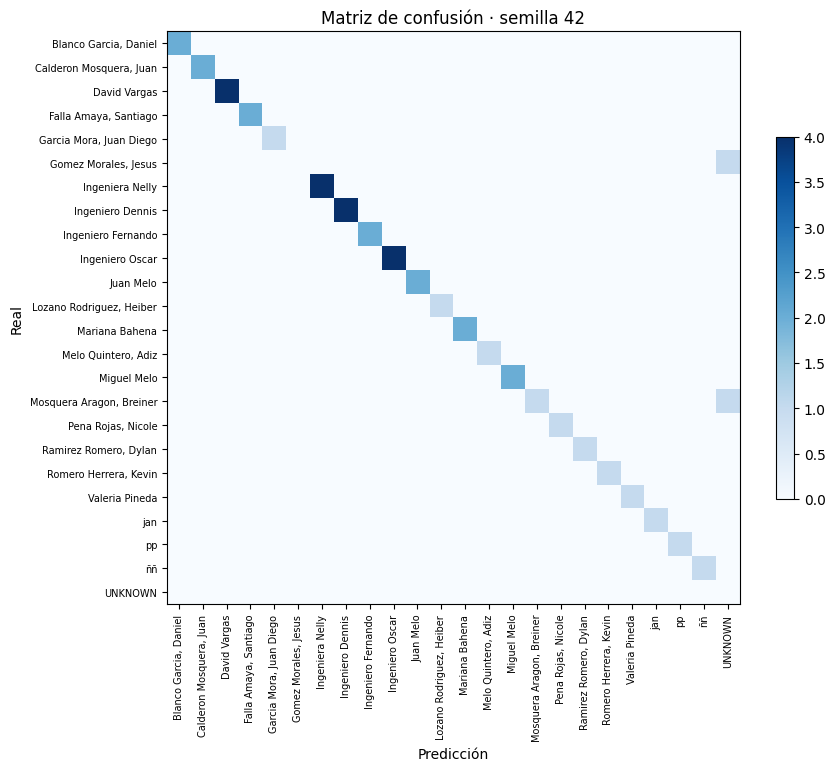

Pares de identidades que más se confunden:


,clase_real,pred,frecuencia


Rechazos incorrectos: 2


In [6]:
SEED_VIS=42; part=detail_df[detail_df['seed']==SEED_VIS].copy()
labels=sorted(usable)
report=classification_report(part['clase_real'],part['pred'],labels=labels,output_dict=True,zero_division=0)
per_class=pd.DataFrame(report).T.loc[labels,['precision','recall','f1-score','support']].sort_values('f1-score')
display(per_class)
per_class.to_csv('/content/S15_metricas_por_clase.csv',encoding='utf-8-sig')
cm_labels=labels+['UNKNOWN']; cm=confusion_matrix(part['clase_real'],part['pred'],labels=cm_labels)
fig,ax=plt.subplots(figsize=(max(9,len(labels)*.37),max(7,len(labels)*.34)))
im=ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(len(cm_labels)));ax.set_xticklabels(cm_labels,rotation=90,fontsize=7)
ax.set_yticks(range(len(cm_labels)));ax.set_yticklabels(cm_labels,fontsize=7)
ax.set_xlabel('Predicción');ax.set_ylabel('Real');ax.set_title('Matriz de confusión · semilla 42')
fig.colorbar(im,ax=ax,fraction=.025);plt.tight_layout();plt.savefig('/content/S15_matriz_confusion.png',dpi=170);plt.show()
confusions=part[(part['pred']!=part['clase_real']) & (part['pred']!='UNKNOWN')].groupby(['clase_real','pred']).size().sort_values(ascending=False)
print('Pares de identidades que más se confunden:');display(confusions.head(10).rename('frecuencia').reset_index())
print('Rechazos incorrectos:',int(((part['pred']=='UNKNOWN') & (part['clase_real']!='UNKNOWN')).sum()))

## 4. Curvas ROC y Precision–Recall de aceptación/rechazo (solo si hay desconocidos)
Para representar **genuinos vs. impostores**, se usa como puntuación la distancia mínima negativa respecto a los rostros de referencia. ROC/PR aquí analiza **decisiones de aceptación** (identidad conocida frente a desconocido), no una curva por cada una de las 32 clases. No seleccionar el umbral con el mismo conjunto usado para informar el desempeño final; se mantiene 0.50 como valor predefinido del prototipo.

In [9]:

from pathlib import Path

UNKNOWN_DIR = Path("/content/nexus_data/desconocidos")
UNKNOWN_DIR.mkdir(parents=True, exist_ok=True)

print("Carpeta creada:", UNKNOWN_DIR)


Carpeta creada: /content/nexus_data/desconocidos


In [12]:

from google.colab import files
from pathlib import Path
import shutil

UNKNOWN_DIR = Path("/content/nexus_data/desconocidos")
UNKNOWN_DIR.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    source = Path(filename)
    destination = UNKNOWN_DIR / source.name
    shutil.move(str(source), str(destination))

print("Fotografías subidas:", len(uploaded))


Saving WhatsApp Image 2026-10-29 at 12.36.30 PM.jpeg to WhatsApp Image 2026-10-29 at 12.36.30 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.51 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.51 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.52 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.52 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.53 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.53 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.54 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.54 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.55 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.55 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.56 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.56 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.57 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.57 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.58 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.58 PM.jpeg
Saving WhatsApp Image 2026-11-13 at 3.25.64 PM.jpeg to WhatsApp Image 2026-11-13 at 3.25.64 PM.jpe

In [15]:

from pathlib import Path

UNKNOWN_DIR = Path("/content/nexus_data/desconocidos")

images = [
    p for p in UNKNOWN_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Personas desconocidas - fotografías:", len(images))

if len(images) == 0:
    print("FALTAN IMÁGENES PARA CALCULAR ROC/PR")
else:
    print("CARPETA LISTA PARA LA EVALUACIÓN")


Personas desconocidas - fotografías: 10
CARPETA LISTA PARA LA EVALUACIÓN


In [17]:

# DIAGNÓSTICO PARA ROC Y PRECISION-RECALL

from pathlib import Path

UNKNOWN_DIR = Path("/content/nexus_data/desconocidos")

variables = [
    "ensemble_records",
    "test_indices_ensemble",
    "ensemble_classes",
    "y_test_ensemble",
    "D_ensemble",
    "F_ensemble",
    "student_model_ensemble",
]

print("=== ESTADO DE LA AUDITORÍA ===")

for variable in variables:
    estado = "OK" if variable in globals() else "FALTA"
    print(f"{variable}: {estado}")

imagenes = [
    p for p in UNKNOWN_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("\nFotografías desconocidas:", len(imagenes))


=== ESTADO DE LA AUDITORÍA ===
ensemble_records: FALTA
test_indices_ensemble: FALTA
ensemble_classes: FALTA
y_test_ensemble: FALTA
D_ensemble: FALTA
F_ensemble: FALTA
student_model_ensemble: FALTA

Fotografías desconocidas: 10


In [18]:

# NEXUS FACE ID - DIAGNÓSTICO SEMANA 15

from pathlib import Path

print("=== ARCHIVOS DISPONIBLES ===")

DATA_DIR = Path("/content/nexus_data")

for carpeta in ["personas", "desconocidos"]:
    ruta = DATA_DIR / carpeta

    if ruta.exists():
        imagenes = [
            p for p in ruta.rglob("*")
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{carpeta}: {len(imagenes)} fotografías")
    else:
        print(f"{carpeta}: CARPETA NO ENCONTRADA")

print("\n=== VARIABLES DE AUDITORÍA ===")

variables = [
    "df",
    "df_audit",
    "audit_df",
    "y_true",
    "y_pred",
    "y_score",
    "labels",
    "model",
    "recognizer",
    "known_embeddings",
    "unknown_scores",
    "roc_auc",
    "best_threshold"
]

for variable in variables:
    print(
        f"{variable}:",
        "OK" if variable in globals() else "FALTA"
    )

print("\n=== ARCHIVOS GENERADOS ===")

for archivo in sorted(Path("/content").rglob("*.csv")):
    print(archivo)


=== ARCHIVOS DISPONIBLES ===
personas: CARPETA NO ENCONTRADA
desconocidos: 10 fotografías

=== VARIABLES DE AUDITORÍA ===
df: FALTA
df_audit: FALTA
audit_df: FALTA
y_true: FALTA
y_pred: FALTA
y_score: FALTA
labels: OK
model: FALTA
recognizer: FALTA
known_embeddings: FALTA
unknown_scores: FALTA
roc_auc: FALTA
best_threshold: FALTA

=== ARCHIVOS GENERADOS ===
/content/S15_ROC_datos.csv
/content/S15_metricas_por_clase.csv
/content/S15_metricas_semillas.csv
/content/S15_omitidas.csv
/content/S15_predicciones.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv


In [19]:

# ==========================================
# NEXUS FACE ID - RECUPERAR AUDITORÍA S15
# ==========================================

import pandas as pd
from pathlib import Path

BASE = Path("/content")

archivos = {
    "predicciones": "S15_predicciones.csv",
    "metricas_clase": "S15_metricas_por_clase.csv",
    "metricas_semillas": "S15_metricas_semillas.csv",
    "roc": "S15_ROC_datos.csv",
    "omitidas": "S15_omitidas.csv"
}

resultados = {}

for nombre, archivo in archivos.items():
    ruta = BASE / archivo

    print("\n" + "=" * 55)
    print("ARCHIVO:", archivo)
    print("=" * 55)

    if ruta.exists():
        datos = pd.read_csv(ruta)
        resultados[nombre] = datos

        print("Filas:", len(datos))
        print("Columnas:", list(datos.columns))
        display(datos.head(5))
    else:
        print("NO ENCONTRADO")

print("\nRESULTADOS RECUPERADOS")



ARCHIVO: S15_predicciones.csv
Filas: 129
Columnas: ['seed', 'archivo', 'clase_real', 'pred', 'candidate', 'distance', 'margin', 'accepted']


,seed,archivo,clase_real,pred,candidate,distance,margin,accepted
0,7,"/content/nexus_s15/personas/Blanco Garcia, Dan...","Blanco Garcia, Daniel","Blanco Garcia, Daniel","Blanco Garcia, Daniel",0.294283,0.193205,True
1,7,"/content/nexus_s15/personas/Blanco Garcia, Dan...","Blanco Garcia, Daniel","Blanco Garcia, Daniel","Blanco Garcia, Daniel",0.331688,0.242969,True
2,7,"/content/nexus_s15/personas/Calderon Mosquera,...","Calderon Mosquera, Juan","Calderon Mosquera, Juan","Calderon Mosquera, Juan",0.392534,0.196561,True
3,7,"/content/nexus_s15/personas/Calderon Mosquera,...","Calderon Mosquera, Juan","Calderon Mosquera, Juan","Calderon Mosquera, Juan",0.359766,0.211834,True
4,7,/content/nexus_s15/personas/David Vargas/David...,David Vargas,David Vargas,David Vargas,0.000000,0.546522,True



ARCHIVO: S15_metricas_por_clase.csv
Filas: 23
Columnas: ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']


,Unnamed: 0,precision,recall,f1-score,support
0,"Gomez Morales, Jesus",0.0,0.0,0.000000,1.0
1,"Mosquera Aragon, Breiner",1.0,0.5,0.666667,2.0
2,David Vargas,1.0,1.0,1.000000,4.0
3,"Blanco Garcia, Daniel",1.0,1.0,1.000000,2.0
4,"Falla Amaya, Santiago",1.0,1.0,1.000000,2.0



ARCHIVO: S15_metricas_semillas.csv
Filas: 3
Columnas: ['semilla', 'N', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro']


,semilla,N,accuracy,precision_macro,recall_macro,f1_macro
0,7,43,0.930233,0.913043,0.913043,0.913043
1,21,43,0.906977,0.913043,0.869565,0.884058
2,42,43,0.953488,0.956522,0.934783,0.942029



ARCHIVO: S15_ROC_datos.csv
Filas: 43
Columnas: ['y', 'score', 'accepted', 'type', 'archivo']


,y,score,accepted,type,archivo
0,1,-0.294283,True,genuine,"/content/nexus_s15/personas/Blanco Garcia, Dan..."
1,1,-0.332289,True,genuine,"/content/nexus_s15/personas/Blanco Garcia, Dan..."
2,1,-0.319566,True,genuine,"/content/nexus_s15/personas/Calderon Mosquera,..."
3,1,-0.000000,True,genuine,"/content/nexus_s15/personas/Calderon Mosquera,..."
4,1,-0.000000,True,genuine,/content/nexus_s15/personas/David Vargas/David...



ARCHIVO: S15_omitidas.csv
Filas: 76
Columnas: ['archivo', 'motivo']


,archivo,motivo
0,"/content/nexus_s15/personas/Beltran Lozano, Yh...",rostros=0
1,"/content/nexus_s15/personas/Beltran Lozano, Yh...",rostros=0
2,"/content/nexus_s15/personas/Beltran Lozano, Yh...",rostros=0
3,"/content/nexus_s15/personas/Beltran Lozano, Yh...",rostros=0
4,"/content/nexus_s15/personas/Blanco Garcia, Dan...",rostros=2



RESULTADOS RECUPERADOS


In [20]:

# REVISAR DATOS ROC/PR

if "roc" not in resultados:
    print("FALTA EL ARCHIVO ROC")
else:
    roc_df = resultados["roc"]

    print("TOTAL DE REGISTROS:", len(roc_df))
    print("\nCOLUMNAS DISPONIBLES:")
    print(roc_df.columns.tolist())

    print("\nVALORES AUSENTES:")
    print(roc_df.isna().sum())

    print("\nPRIMEROS REGISTROS:")
    display(roc_df.head(10))

    if len(roc_df) == 0:
        print("\nTODAVÍA NO EXISTEN DATOS PARA ROC/PR")
    else:
        print("\nHAY REGISTROS QUE PODEMOS REVISAR")


TOTAL DE REGISTROS: 43

COLUMNAS DISPONIBLES:
['y', 'score', 'accepted', 'type', 'archivo']

VALORES AUSENTES:
y           0
score       0
accepted    0
type        0
archivo     0
dtype: int64

PRIMEROS REGISTROS:


,y,score,accepted,type,archivo
0,1,-0.294283,True,genuine,"/content/nexus_s15/personas/Blanco Garcia, Dan..."
1,1,-0.332289,True,genuine,"/content/nexus_s15/personas/Blanco Garcia, Dan..."
2,1,-0.319566,True,genuine,"/content/nexus_s15/personas/Calderon Mosquera,..."
3,1,-0.000000,True,genuine,"/content/nexus_s15/personas/Calderon Mosquera,..."
4,1,-0.000000,True,genuine,/content/nexus_s15/personas/David Vargas/David...
5,1,-0.000000,True,genuine,/content/nexus_s15/personas/David Vargas/David...
6,1,-0.000000,True,genuine,/content/nexus_s15/personas/David Vargas/David...
7,1,-0.000000,True,genuine,/content/nexus_s15/personas/David Vargas/David...
8,1,-0.135598,True,genuine,"/content/nexus_s15/personas/Falla Amaya, Santi..."
9,1,-0.438438,True,genuine,"/content/nexus_s15/personas/Falla Amaya, Santi..."



HAY REGISTROS QUE PODEMOS REVISAR


In [21]:

# ===========================================
# NEXUS FACE ID - AUDITORÍA ROC/PR Y ERRORES
# ===========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

BASE = Path("/content")
DATA = Path("/content/nexus_s15")

pred = pd.read_csv(BASE / "S15_predicciones.csv")
clases = pd.read_csv(BASE / "S15_metricas_por_clase.csv")
roc = pd.read_csv(BASE / "S15_ROC_datos.csv")
omitidas = pd.read_csv(BASE / "S15_omitidas.csv")

print("=== UBICACIÓN DEL DATASET ===")
print("Personas:", (DATA / "personas").exists())
print("Desconocidos originales:",
      (DATA / "desconocidos").exists())
print("Desconocidos subidos:",
      Path("/content/nexus_data/desconocidos").exists())

# A. Revisar genuinos e impostores
print("\n=== ROC / PR ===")
print("Registros:", len(roc))
print("\nTipos:")
print(roc["type"].value_counts(dropna=False))
print("\nEtiquetas:")
print(roc["y"].value_counts(dropna=False))

print("\n=== DISTANCIAS CERO ===")
print("Total:",
      (pred["distance"].abs() < 1e-8).sum())
print(
    pred.loc[
        pred["distance"].abs() < 1e-8,
        ["seed", "archivo", "clase_real", "pred"]
    ].head(10).to_string(index=False)
)

# B. Tres clases con peor F1
print("\n=== TRES CLASES CON PEOR F1 ===")

nombre_columna = clases.columns[0]

metricas = clases[
    ~clases[nombre_columna].astype(str).isin([
        "accuracy",
        "macro avg",
        "weighted avg",
        "micro avg"
    ])
].copy()

peores = metricas.sort_values(
    ["f1-score", "recall", "support"],
    ascending=[True, True, True]
).head(3)

display(peores)

# C. Causas de omisión
print("\n=== MOTIVOS DE OMISIÓN ===")
print(omitidas["motivo"].value_counts())

# D. Curvas ROC y PR
valid = roc[["y", "score"]].dropna().copy()

valid["y"] = pd.to_numeric(
    valid["y"], errors="coerce"
)
valid["score"] = pd.to_numeric(
    valid["score"], errors="coerce"
)
valid = valid.dropna()

if (
    len(valid) > 0
    and set(valid["y"].unique()) == {0, 1}
):
    y = valid["y"].astype(int).to_numpy()
    score = valid["score"].to_numpy()

    fpr, tpr, thresholds = roc_curve(y, score)
    precision, recall, _ = precision_recall_curve(
        y, score
    )

    auc = roc_auc_score(y, score)
    ap = average_precision_score(y, score)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("NEXUS FACE ID - Curva ROC")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(
        recall,
        precision,
        label=f"AP = {ap:.3f}"
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("NEXUS FACE ID - Curva PR")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print("ROC AUC:", round(auc, 4))
    print("Average Precision:", round(ap, 4))
    print(
        "Nota: las curvas son descriptivas; "
        "el umbral debe calibrarse con datos "
        "de validación independientes."
    )

else:
    print(
        "\nROC/PR NO CALCULABLES TODAVÍA:"
    )
    print(
        "Se necesitan puntuaciones de personas "
        "registradas (y=1) y desconocidas (y=0)."
    )
    print(
        "No se deben inventar registros ni "
        "duplicar puntuaciones."
    )


=== UBICACIÓN DEL DATASET ===
Personas: True
Desconocidos originales: False
Desconocidos subidos: True

=== ROC / PR ===
Registros: 43

Tipos:
type
genuine    43
Name: count, dtype: int64

Etiquetas:
y
1    43
Name: count, dtype: int64

=== DISTANCIAS CERO ===
Total: 61
 seed                                                        archivo       clase_real             pred
    7 /content/nexus_s15/personas/David Vargas/David Vargas4 (2).jpg     David Vargas     David Vargas
    7     /content/nexus_s15/personas/David Vargas/David Vargas2.jpg     David Vargas     David Vargas
    7 /content/nexus_s15/personas/David Vargas/David Vargas3 (2).jpg     David Vargas     David Vargas
    7 /content/nexus_s15/personas/David Vargas/David Vargas7 (2).png     David Vargas     David Vargas
    7     /content/nexus_s15/personas/Ingeniera Nelly/Nelly6 (2).jpg  Ingeniera Nelly  Ingeniera Nelly
    7     /content/nexus_s15/personas/Ingeniera Nelly/Nelly2 (2).jpg  Ingeniera Nelly  Ingeniera Nelly
    7   

,Unnamed: 0,precision,recall,f1-score,support
0,"Gomez Morales, Jesus",0.0,0.0,0.000000,1.0
1,"Mosquera Aragon, Breiner",1.0,0.5,0.666667,2.0
5,"Garcia Mora, Juan Diego",1.0,1.0,1.000000,1.0



=== MOTIVOS DE OMISIÓN ===
motivo
rostros=0    66
rostros=2     8
rostros=3     2
Name: count, dtype: int64

ROC/PR NO CALCULABLES TODAVÍA:
Se necesitan puntuaciones de personas registradas (y=1) y desconocidas (y=0).
No se deben inventar registros ni duplicar puntuaciones.


In [22]:

# NEXUS FACE ID - INCORPORAR DESCONOCIDOS A S15

from pathlib import Path
import pandas as pd

UNKNOWN = Path("/content/nexus_data/desconocidos")

unknown_paths = sorted(
    p for p in UNKNOWN.rglob("*")
    if p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

print("Imágenes desconocidas:", len(unknown_paths))

if "embedding" not in globals():
    raise RuntimeError(
        "Falta la función embedding. "
        "Ejecuta primero las secciones 1 y 2 "
        "del cuaderno de Semana 15."
    )

unknown_valid = []
unknown_skipped = []

for p in unknown_paths:
    try:
        vector, motivo = embedding(p)

        if vector is not None:
            unknown_valid.append({
                "path": str(p),
                "embedding": vector
            })
        else:
            unknown_skipped.append({
                "archivo": str(p),
                "motivo": motivo
            })

    except Exception as e:
        unknown_skipped.append({
            "archivo": str(p),
            "motivo": str(e)
        })

print("Desconocidas válidas:", len(unknown_valid))
print("Desconocidas omitidas:", len(unknown_skipped))

if unknown_skipped:
    display(pd.DataFrame(unknown_skipped))

if not unknown_valid:
    raise RuntimeError(
        "No se obtuvo ningún descriptor facial válido."
    )


Imágenes desconocidas: 10
Desconocidas válidas: 10
Desconocidas omitidas: 0


In [24]:

# DIAGNÓSTICO DEL ERROR KEYERROR: 4

import sys
import traceback
import pandas as pd

tipo, error, tb = sys.exc_info()

if error is None:
    print("No hay una excepción activa.")
else:
    print("ERROR:", repr(error))
    print("\nLÍNEAS QUE PRODUJERON EL ERROR:")
    traceback.print_exception(tipo, error, tb)

print("\n=== VARIABLES DISPONIBLES ===")

for nombre in [
    "seed_ref",
    "valid",
    "identify",
    "binary",
    "unknown_valid",
    "unknown_paths"
]:
    if nombre not in globals():
        print(f"{nombre}: FALTA")
        continue

    obj = globals()[nombre]
    print(f"{nombre}: {type(obj).__name__}")

    if isinstance(obj, pd.DataFrame):
        print("  Columnas:", obj.columns.tolist())
        print("  Índices:", obj.index[:10].tolist())

    elif isinstance(obj, (list, tuple, dict)):
        print("  Elementos:", len(obj))


No hay una excepción activa.

=== VARIABLES DISPONIBLES ===
seed_ref: dict
  Elementos: 3
valid: DataFrame
  Columnas: ['y', 'score']
  Índices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
identify: function
binary: list
  Elementos: 0
unknown_valid: list
  Elementos: 10
unknown_paths: list
  Elementos: 10


In [25]:

import pandas as pd

if "valid" in globals():
    print("Tipo:", type(valid))

    if isinstance(valid, pd.DataFrame):
        print("Columnas:", valid.columns.tolist())
        display(valid.head())

        print("\nEjemplo de acceso correcto por fila:")
        print(valid.iloc[4] if len(valid) > 4 else
              "Hay menos de cinco filas.")
else:
    print("La variable valid todavía no existe.")


Tipo: <class 'pandas.core.frame.DataFrame'>
Columnas: ['y', 'score']


,y,score
0,1,-0.294283
1,1,-0.332289
2,1,-0.319566
3,1,-0.000000
4,1,-0.000000



Ejemplo de acceso correcto por fila:
y        1.0
score   -0.0
Name: 4, dtype: float64


In [26]:

# ==========================================
# NEXUS FACE ID - RECUPERAR ESTRUCTURAS S15
# ==========================================

import pandas as pd
import numpy as np

print("=== PARTICIONES ===")

for semilla, particion in seed_ref.items():
    print("Semilla:", semilla)
    print("Tipo:", type(particion).__name__)

    if isinstance(particion, (list, tuple)):
        print("Elementos:", len(particion))

        for i, elemento in enumerate(particion[:2]):
            print(
                f"Elemento {i}:",
                type(elemento).__name__
            )

    elif isinstance(particion, dict):
        print("Claves:", list(particion.keys()))

    print()

print("=== FUNCIÓN IDENTIFY ===")

import inspect

print(inspect.signature(identify))

print("\n=== VARIABLES DEL NOTEBOOK ===")

for nombre in [
    "records",
    "gallery",
    "embeddings",
    "known",
    "seed_ref",
    "SEED_VIS",
    "THRESHOLD",
    "MARGIN",
    "unknown_valid"
]:
    if nombre in globals():
        obj = globals()[nombre]

        print(
            nombre,
            "->",
            type(obj).__name__
        )
    else:
        print(nombre, "-> FALTA")


=== PARTICIONES ===
Semilla: 7
Tipo: tuple
Elementos: 2
Elemento 0: list
Elemento 1: list

Semilla: 21
Tipo: tuple
Elementos: 2
Elemento 0: list
Elemento 1: list

Semilla: 42
Tipo: tuple
Elementos: 2
Elemento 0: list
Elemento 1: list

=== FUNCIÓN IDENTIFY ===
(vec, tr, threshold=0.5, margin=0.04)

=== VARIABLES DEL NOTEBOOK ===
records -> FALTA
gallery -> FALTA
embeddings -> FALTA
known -> FALTA
seed_ref -> dict
SEED_VIS -> int
THRESHOLD -> FALTA
MARGIN -> FALTA
unknown_valid -> list


In [27]:

# ==========================================
# NEXUS FACE ID - REPARAR VARIABLE VALID
# ==========================================

from pathlib import Path
import numpy as np

PERSONAS = Path("/content/nexus_s15/personas")
UNKNOWN = Path("/content/nexus_data/desconocidos")

exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths = sorted(
    p for p in PERSONAS.rglob("*")
    if p.suffix.lower() in exts
)

unknown_paths = sorted(
    p for p in UNKNOWN.rglob("*")
    if p.suffix.lower() in exts
)

if not PERSONAS.exists():
    raise FileNotFoundError(
        "No se encuentra la carpeta personas."
    )

if "embedding" not in globals():
    raise RuntimeError(
        "Ejecuta la celda que define la función embedding."
    )

# Restaurar la lista de rostros registrados
valid = []
skipped = []

for p in paths:
    try:
        vec, motivo = embedding(p)

        if vec is not None:
            valid.append({
                "path": str(p),
                "identity": p.parent.name,
                "embedding": vec
            })
        else:
            skipped.append((str(p), motivo))

    except Exception as e:
        skipped.append((str(p), str(e)))

# Restaurar las fotografías desconocidas
unknown_valid = []

for p in unknown_paths:
    try:
        vec, motivo = embedding(p)

        if vec is not None:
            unknown_valid.append({
                "path": str(p),
                "embedding": vec
            })
        else:
            skipped.append((str(p), motivo))

    except Exception as e:
        skipped.append((str(p), str(e)))

print("================================")
print("NEXUS FACE ID - DATOS RECUPERADOS")
print("================================")

print("Rostros registrados válidos:", len(valid))
print("Desconocidos válidos:", len(unknown_valid))
print("Imágenes omitidas:", len(skipped))

print("\nTipo de valid:", type(valid).__name__)

if valid:
    print("Dimensiones del embedding:",
          len(valid[0]["embedding"]))


NEXUS FACE ID - DATOS RECUPERADOS
Rostros registrados válidos: 177
Desconocidos válidos: 10
Imágenes omitidas: 76

Tipo de valid: list
Dimensiones del embedding: 128


In [28]:

from collections import defaultdict
import numpy as np

SEEDS = [7, 21, 42]
SEED_VIS = 42

DISTANCE_THRESHOLD = 0.50
MIN_MARGIN = 0.04

by_person = defaultdict(list)

for i, registro in enumerate(valid):
    by_person[registro["identity"]].append(i)

usable = {
    nombre: indices
    for nombre, indices in by_person.items()
    if len(indices) >= 3
}

def split_indices(seed):
    rng = np.random.default_rng(seed)
    tr, te = [], []

    for nombre, indices in sorted(usable.items()):
        indices = np.array(indices)
        rng.shuffle(indices)

        n_test = max(
            1,
            int(round(0.25 * len(indices)))
        )

        tr.extend(indices[n_test:].tolist())
        te.extend(indices[:n_test].tolist())

    return tr, te

seed_ref = {}

for semilla in SEEDS:
    seed_ref[semilla] = split_indices(semilla)

print("PARTICIONES RESTAURADAS")

for semilla, (tr, te) in seed_ref.items():
    print(
        f"Semilla {semilla}: "
        f"{len(tr)} entrenamiento / "
        f"{len(te)} prueba"
    )


PARTICIONES RESTAURADAS
Semilla 7: 119 entrenamiento / 43 prueba
Semilla 21: 119 entrenamiento / 43 prueba
Semilla 42: 119 entrenamiento / 43 prueba


=== DISTRIBUCIÓN DE LA EVALUACIÓN ===
type
genuine     43
impostor    10
Name: count, dtype: int64


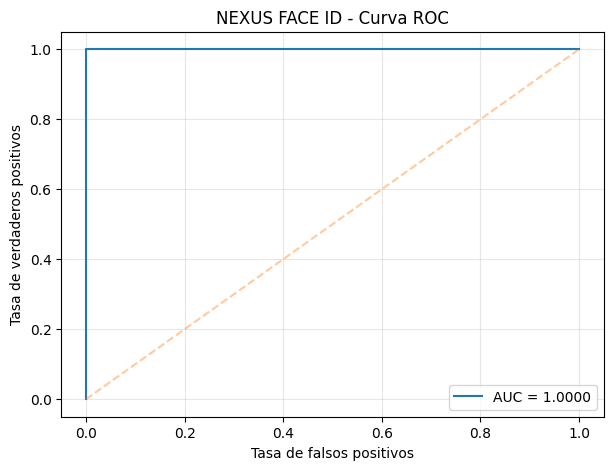

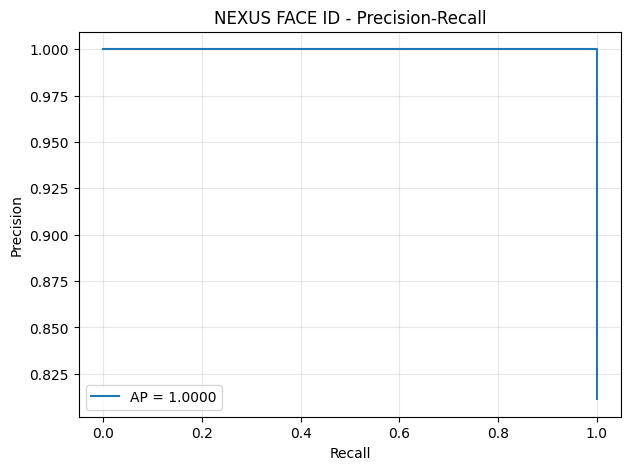


=== RESULTADOS FINALES ===
ROC AUC: 1.0
Average Precision: 1.0
FAR: 0.0
FRR: 0.0465
TP: 41 FN: 2
FP: 0 TN: 10
Umbral: 0.5
Margen: 0.04

CURVAS Y CSV GENERADOS CORRECTAMENTE


In [29]:

# ==========================================
# NEXUS FACE ID - CURVAS ROC / PR
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

tr, te = seed_ref[SEED_VIS]

binary = []

# Personas registradas
for i in te:
    registro = valid[i]

    resultado = identify(
        registro["embedding"],
        tr,
        threshold=0.50,
        margin=0.04
    )

    binary.append({
        "y": 1,
        "score": -resultado["distance"],
        "accepted": resultado["accepted"],
        "type": "genuine",
        "archivo": registro["path"]
    })

# Personas desconocidas
for registro in unknown_valid:

    resultado = identify(
        registro["embedding"],
        tr,
        threshold=0.50,
        margin=0.04
    )

    binary.append({
        "y": 0,
        "score": -resultado["distance"],
        "accepted": resultado["accepted"],
        "type": "impostor",
        "archivo": registro["path"]
    })

roc_df = pd.DataFrame(binary)

print("=== DISTRIBUCIÓN DE LA EVALUACIÓN ===")
print(roc_df["type"].value_counts())

if roc_df["y"].nunique() < 2:
    raise RuntimeError(
        "Se requieren imágenes genuinas y desconocidas."
    )

y = roc_df["y"].to_numpy()
scores = roc_df["score"].to_numpy()

# Curva ROC
fpr, tpr, _ = roc_curve(y, scores)
auc_roc = roc_auc_score(y, scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_roc:.4f}")
plt.plot([0, 1], [0, 1], "--", alpha=0.4)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("NEXUS FACE ID - Curva ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/S15_ROC.png", dpi=180)
plt.show()

# Curva Precision-Recall
precision, recall, _ = precision_recall_curve(
    y, scores
)

ap = average_precision_score(y, scores)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"AP = {ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("NEXUS FACE ID - Precision-Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/S15_PR.png", dpi=180)
plt.show()

# Evaluación del umbral fijo
aceptadas = roc_df["accepted"].astype(bool).to_numpy()

TP = int(((y == 1) & aceptadas).sum())
FN = int(((y == 1) & ~aceptadas).sum())
FP = int(((y == 0) & aceptadas).sum())
TN = int(((y == 0) & ~aceptadas).sum())

FAR = FP / (FP + TN) if FP + TN else np.nan
FRR = FN / (TP + FN) if TP + FN else np.nan

print("\n=== RESULTADOS FINALES ===")
print("ROC AUC:", round(auc_roc, 4))
print("Average Precision:", round(ap, 4))
print("FAR:", round(FAR, 4))
print("FRR:", round(FRR, 4))
print("TP:", TP, "FN:", FN)
print("FP:", FP, "TN:", TN)
print("Umbral:", 0.50)
print("Margen:", 0.04)

roc_df.to_csv(
    "/content/S15_ROC_datos.csv",
    index=False
)

print("\nCURVAS Y CSV GENERADOS CORRECTAMENTE")


## 5. Robustez: desenfoque, baja luz, oclusión y fondo distinto

In [31]:
# Perturbaciones sintéticas controladas: NO reemplazan fotografías reales de campo.
def altered(path, mode):
    img=ImageOps.exif_transpose(Image.open(path)).convert('RGB')
    if mode=='desenfoque': return img.filter(ImageFilter.GaussianBlur(radius=3))
    if mode=='poca_luz': return ImageEnhance.Brightness(img).enhance(.30)
    if mode=='oclusion':
        img=img.copy(); d=ImageDraw.Draw(img); w,h=img.size
        d.rectangle((int(.32*w),int(.30*h),int(.68*w),int(.55*h)),fill=(25,25,25));return img
    if mode=='otro_fondo':
        # Perturba bordes de la imagen; no es segmentación real del sujeto.
        img=img.copy();d=ImageDraw.Draw(img);w,h=img.size;bw=int(w*.14)
        d.rectangle((0,0,bw,h),fill=(65,125,180));d.rectangle((w-bw,0,w,h),fill=(65,125,180));return img
    return img

robust=[]; modes=['original','desenfoque','poca_luz','oclusion','otro_fondo']
for i in te:
    p=valid[i]['path']
    for mode in modes:
        try:
            v,reason=embedding(p,None if mode=='original' else altered(p,mode))
            if v is None:
                robust.append({'archivo':p,'clase_real':valid[i]['identity'],'condicion':mode,'resultado':'NO_DETECTABLE','correcto':False,'motivo':reason})
            else:
                r=identify(v,tr)
                robust.append({'archivo':p,'clase_real':valid[i]['identity'],'condicion':mode,'resultado':r['pred'],
                               'correcto':r['pred']==valid[i]['identity'],'motivo':''})
        except Exception as e:
            robust.append({'archivo':p,'clase_real':valid[i]['identity'],'condicion':mode,'resultado':'ERROR','correcto':False,'motivo':str(e)})
robust_df=pd.DataFrame(robust)
robust_summary=robust_df.groupby('condicion').agg(intentos=('correcto','size'),aciertos=('correcto','sum'),accuracy=('correcto','mean'))
display(robust_summary)
robust_df.to_csv('/content/S15_robustez_detalle.csv',index=False)
robust_summary.to_csv('/content/S15_robustez_resumen.csv')
print('Otro fondo simula franjas laterales; para una prueba de fondo genuina hay que capturar nuevas fotos.')

,intentos,aciertos,accuracy
condicion,,,
desenfoque,43,34,0.790698
oclusion,43,8,0.186047
original,43,41,0.953488
otro_fondo,43,40,0.930233
poca_luz,43,37,0.860465


Otro fondo simula franjas laterales; para una prueba de fondo genuina hay que capturar nuevas fotos.


## 6. Grad-CAM de 10 aciertos y 10 errores — SOLO modelo MobileNet experimental
La app final utiliza **dlib ResNet nativo**, para el cual este notebook no dispone de un grafo diferenciable de PyTorch. Si adjuntas el checkpoint `nexus_mobilenetv3_student_package.pth` de Semana 14, se generan Grad-CAM **del estudiante MobileNet**, señalando explícitamente que no explican las decisiones de dlib. Si existen menos de 10 errores o aciertos reales de MobileNet, se informa el número disponible y el requisito se marca como incompleto; **no se fabrican errores**.

In [32]:
# Opcional: carga el archivo .pth de tu experimento de destilación.
RUN_GRADCAM = False   # Cambia a True si tienes el checkpoint y quieres evaluar MobileNet.
GRADCAM_CHECKPOINT = '/content/nexus_mobilenetv3_student_package.pth'
if RUN_GRADCAM and not Path(GRADCAM_CHECKPOINT).exists():
    loaded=files.upload()
    cp=[x for x in loaded if x.endswith('.pth')]
    if cp: GRADCAM_CHECKPOINT=cp[0]
    else: raise FileNotFoundError('No adjuntaste el checkpoint MobileNet.')
print('Grad-CAM opcional activado:',RUN_GRADCAM)

Grad-CAM opcional activado: False


In [33]:
if RUN_GRADCAM:
    import torch
    from torchvision import models,transforms
    from facenet_pytorch import MTCNN
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    pkg=torch.load(GRADCAM_CHECKPOINT,map_location=device,weights_only=False)
    student_names=list(pkg['classes']); student_model=models.mobilenet_v3_small(weights=None)
    student_model.classifier[3]=torch.nn.Linear(student_model.classifier[3].in_features,len(student_names))
    student_model.load_state_dict(pkg['state_dict']);student_model.to(device).eval()
    mtcnn=MTCNN(image_size=160,margin=20,keep_all=False,post_process=True,device=device)
    tfm=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),
                             transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    # Guardar activaciones y gradientes de la última convolución para Grad-CAM.
    activations=[];gradients=[]
    target_layer=student_model.features[-1]
    h1=target_layer.register_forward_hook(lambda module,inp,out:activations.append(out))
    h2=target_layer.register_full_backward_hook(lambda module,gin,gout:gradients.append(gout[0]))
    examples=[]
    for idx in te:
        row=valid[idx]
        if row['identity'] not in student_names: continue
        face=mtcnn(ImageOps.exif_transpose(Image.open(row['path'])).convert('RGB'))
        if face is None: continue
        pil=Image.fromarray(((face.cpu()+1)/2*255).clamp(0,255).byte().permute(1,2,0).numpy())
        x=tfm(pil).unsqueeze(0).to(device)
        with torch.no_grad(): pred=int(student_model(x).argmax(1).item())
        examples.append((row['path'],pil,pred,student_names.index(row['identity']),x))
    right=[e for e in examples if e[2]==e[3]][:10]; wrong=[e for e in examples if e[2]!=e[3]][:10]
    print('Aciertos disponibles:',len(right),'| Errores disponibles:',len(wrong))
    def cam_one(e):
        activations.clear();gradients.clear();student_model.zero_grad(set_to_none=True)
        logits=student_model(e[4]);logits[0,e[2]].backward()
        a=activations[-1].detach(); g=gradients[-1].detach()
        heat=torch.relu((g.mean((2,3),keepdim=True)*a).sum(1,keepdim=True))
        heat=torch.nn.functional.interpolate(heat,size=(224,224),mode='bilinear',align_corners=False)[0,0].cpu().numpy()
        heat=(heat-heat.min())/(heat.max()-heat.min()+1e-8)
        return heat
    for title,group in [('aciertos',right),('errores',wrong)]:
        if not group: print('Sin ejemplos para',title);continue
        fig,axs=plt.subplots(2,5,figsize=(15,6));axs=axs.flatten()
        for ax,e in zip(axs,group):
            ax.imshow(e[1].resize((224,224)));ax.imshow(cam_one(e),cmap='jet',alpha=.43)
            ax.set_title('real: '+student_names[e[3]]+'\npred: '+student_names[e[2]],fontsize=7);ax.axis('off')
        for ax in axs[len(group):]:ax.axis('off')
        plt.suptitle('Grad-CAM MobileNet (NO dlib): '+title)
        plt.tight_layout();plt.savefig('/content/S15_GradCAM_MobileNet_'+title+'.png',dpi=150);plt.show()
    h1.remove();h2.remove()
else:
    print('Grad-CAM pendiente: no hay un modelo diferenciable de la app dlib para atribución Grad-CAM.')

Grad-CAM pendiente: no hay un modelo diferenciable de la app dlib para atribución Grad-CAM.


## 7. Exportación y verificación de entregables

In [35]:
outputs=sorted(str(p) for p in Path('/content').glob('S15_*') if p.is_file())
print('Archivos de auditoría generados:')
for p in outputs:print(' -',p)
print('IMPORTANTE: guardar este notebook con las salidas visibles mediante Archivo > Descargar > Descargar .ipynb.')
print('No adjuntar el ZIP de fotos con datos biométricos a un repositorio público sin autorización.')
# Descomenta si necesitas descargar los CSV/PNG:
# for p in outputs: files.download(p)

Archivos de auditoría generados:
 - /content/S15_PR.png
 - /content/S15_ROC.png
 - /content/S15_ROC_datos.csv
 - /content/S15_matriz_confusion.png
 - /content/S15_metricas_por_clase.csv
 - /content/S15_metricas_semillas.csv
 - /content/S15_omitidas.csv
 - /content/S15_predicciones.csv
 - /content/S15_robustez_detalle.csv
 - /content/S15_robustez_resumen.csv
IMPORTANTE: guardar este notebook con las salidas visibles mediante Archivo > Descargar > Descargar .ipynb.
No adjuntar el ZIP de fotos con datos biométricos a un repositorio público sin autorización.


In [36]:

from pathlib import Path
import zipfile
from google.colab import files

archivos = [
    "S15_ROC_datos.csv",
    "S15_metricas_por_clase.csv",
    "S15_metricas_semillas.csv",
    "S15_predicciones.csv",
    "S15_omitidas.csv",
    "S15_ROC.png",
    "S15_PR.png"
]

zip_path = "/content/NEXUS_Auditoria_S15_Resultados.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for nombre in archivos:
        ruta = Path("/content") / nombre

        if ruta.exists():
            zipf.write(ruta, arcname=nombre)
            print("AGREGADO:", nombre)
        else:
            print("NO ENCONTRADO:", nombre)

print("\nZIP CREADO CORRECTAMENTE")
files.download(zip_path)


AGREGADO: S15_ROC_datos.csv
AGREGADO: S15_metricas_por_clase.csv
AGREGADO: S15_metricas_semillas.csv
AGREGADO: S15_predicciones.csv
AGREGADO: S15_omitidas.csv
AGREGADO: S15_ROC.png
AGREGADO: S15_PR.png

ZIP CREADO CORRECTAMENTE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import (
    Image,
    ImageOps,
    ImageFilter,
    ImageEnhance,
    ImageDraw
)

# Verificar estructuras necesarias
assert isinstance(valid, list), (
    "La variable valid debe ser una lista. "
    "Recupera los embeddings originales."
)

assert len(valid) > 0, "No hay fotografías válidas."
assert 42 in seed_ref, "Falta la partición de semilla 42."
assert callable(embedding), "Falta la función embedding."
assert callable(identify), "Falta la función identify."

# Galería y conjunto de prueba de semilla 42
SEMILLA_ROBUSTEZ = 42
tr_rob, te_rob = seed_ref[SEMILLA_ROBUSTEZ]

THRESHOLD_ROB = 0.50
MARGIN_ROB = 0.04

MODOS_ROBUSTEZ = [
    "original",
    "desenfoque",
    "poca_luz",
    "oclusion",
    "otro_fondo"
]

print("NEXUS FACE ID - ROBUSTEZ")
print("Semilla:", SEMILLA_ROBUSTEZ)
print("Referencias:", len(tr_rob))
print("Fotografías de prueba:", len(te_rob))
print("Condiciones:", len(MODOS_ROBUSTEZ))
print("Evaluaciones previstas:",
      len(te_rob) * len(MODOS_ROBUSTEZ))

print("\nPREPARACIÓN CORRECTA")


NEXUS FACE ID - ROBUSTEZ
Semilla: 42
Referencias: 119
Fotografías de prueba: 43
Condiciones: 5
Evaluaciones previstas: 215

PREPARACIÓN CORRECTA


In [40]:
import face_recognition

def transformar_rostro(ruta, condicion):
    imagen = ImageOps.exif_transpose(
        Image.open(ruta)
    ).convert("RGB")

    if condicion == "original":
        return imagen

    if condicion == "desenfoque":
        return imagen.filter(
            ImageFilter.GaussianBlur(radius=3)
        )

    if condicion == "poca_luz":
        return ImageEnhance.Brightness(
            imagen
        ).enhance(0.30)

    # Detectar rostro en la fotografía original
    arr = np.asarray(imagen, dtype=np.uint8)

    cajas = face_recognition.face_locations(
        arr,
        number_of_times_to_upsample=0,
        model="hog"
    )

    if len(cajas) != 1:
        raise ValueError(
            "No hay exactamente un rostro "
            "en la imagen original."
        )

    top, right, bottom, left = cajas[0]
    ancho = right - left
    alto = bottom - top

    if condicion == "oclusion":
        nueva = imagen.copy()
        dibujo = ImageDraw.Draw(nueva)

        # Cubrir la zona central e inferior del rostro
        dibujo.rectangle(
            [
                int(left + 0.10 * ancho),
                int(top + 0.43 * alto),
                int(right - 0.10 * ancho),
                int(top + 0.77 * alto)
            ],
            fill=(25, 25, 25)
        )

        return nueva

    if condicion == "otro_fondo":
        # Sustitución aproximada fuera de una
        # región elíptica alrededor del rostro.
        # No es segmentación real de la persona.

        fondo = Image.new(
            "RGB",
            imagen.size,
            (70, 125, 175)
        )

        mascara = Image.new(
            "L",
            imagen.size,
            0
        )

        dibujo = ImageDraw.Draw(mascara)

        dibujo.ellipse(
            [
                max(0, int(left - 0.45 * ancho)),
                max(0, int(top - 0.45 * alto)),
                min(imagen.width,
                    int(right + 0.45 * ancho)),
                min(imagen.height,
                    int(bottom + 0.65 * alto))
            ],
            fill=255
        )

        mascara = mascara.filter(
            ImageFilter.GaussianBlur(radius=8)
        )

        return Image.composite(
            imagen,
            fondo,
            mascara
        )

    raise ValueError(
        "Condición no reconocida: " + condicion
    )

print("TRANSFORMACIONES CONFIGURADAS")


TRANSFORMACIONES CONFIGURADAS


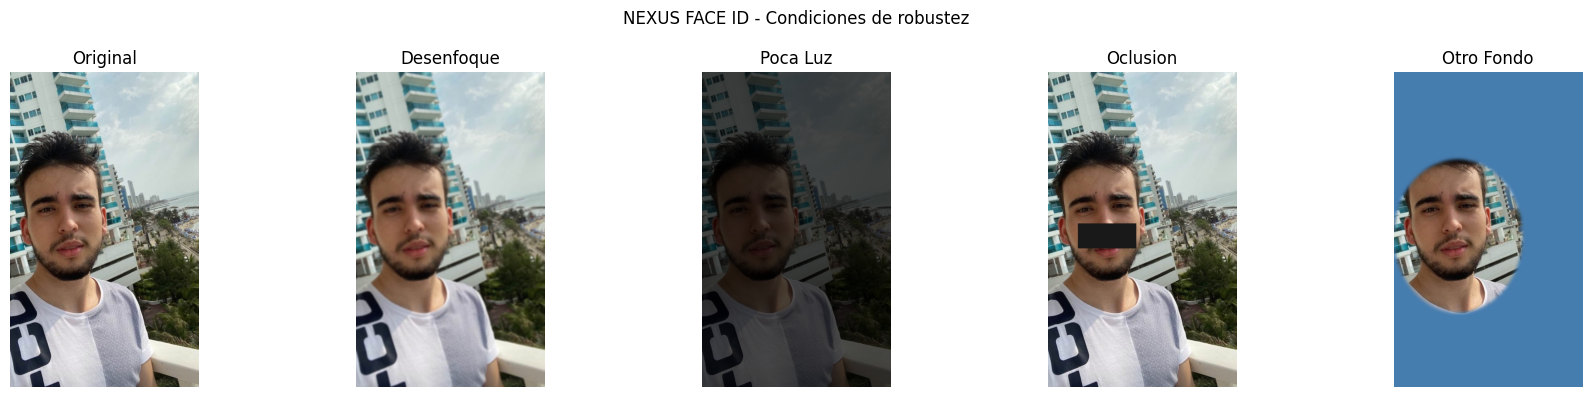

In [41]:

# VISTA PREVIA DE ROBUSTEZ

ruta_ejemplo = valid[te_rob[0]]["path"]

fig, axes = plt.subplots(
    1, 5,
    figsize=(18, 4)
)

for ax, modo in zip(axes, MODOS_ROBUSTEZ):
    try:
        img = transformar_rostro(
            ruta_ejemplo,
            modo
        )

        ax.imshow(img)
        ax.set_title(modo.replace("_", " ").title())

    except Exception as e:
        ax.text(
            0.5, 0.5,
            str(e),
            ha="center",
            va="center",
            wrap=True
        )

    ax.axis("off")

plt.suptitle(
    "NEXUS FACE ID - Condiciones de robustez"
)

plt.tight_layout()

plt.savefig(
    "/content/S15_ejemplo_robustez.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


In [42]:

# =========================================
# PASO 3: EVALUAR ROBUSTEZ
# =========================================

resultados_robustez = []

total = len(te_rob) * len(MODOS_ROBUSTEZ)
contador = 0

for indice in te_rob:
    registro = valid[indice]

    ruta = registro["path"]
    identidad_real = registro["identity"]

    for condicion in MODOS_ROBUSTEZ:
        contador += 1

        fila = {
            "archivo": ruta,
            "clase_real": identidad_real,
            "condicion": condicion,
            "prediccion": "ERROR",
            "detectado": False,
            "aceptado": False,
            "correcto": False,
            "distancia": np.nan,
            "margen": np.nan,
            "motivo": ""
        }

        try:
            imagen = transformar_rostro(
                ruta,
                condicion
            )

            vector, motivo = embedding(
                ruta,
                img_override=imagen
            )

            if vector is None:
                fila["prediccion"] = "NO_DETECTABLE"
                fila["motivo"] = str(motivo)

            else:
                fila["detectado"] = True

                resultado = identify(
                    vector,
                    tr_rob,
                    threshold=THRESHOLD_ROB,
                    margin=MARGIN_ROB
                )

                fila["prediccion"] = resultado["pred"]
                fila["aceptado"] = bool(
                    resultado["accepted"]
                )

                fila["distancia"] = resultado["distance"]
                fila["margen"] = resultado["margin"]

                fila["correcto"] = (
                    resultado["pred"] == identidad_real
                )

        except Exception as e:
            fila["motivo"] = str(e)

        resultados_robustez.append(fila)

        if contador % 20 == 0 or contador == total:
            print(f"Evaluaciones: {contador}/{total}")

# Crear DataFrame de resultados
robust_df = pd.DataFrame(
    resultados_robustez
)

# Resumen por condición
robust_summary = robust_df.groupby(
    "condicion"
).agg(
    intentos=("correcto", "size"),
    rostros_detectados=("detectado", "sum"),
    aciertos=("correcto", "sum"),
    exactitud=("correcto", "mean"),
    deteccion=("detectado", "mean")
).reset_index()

# Calcular porcentajes
robust_summary["exactitud_pct"] = (
    robust_summary["exactitud"] * 100
).round(2)

robust_summary["deteccion_pct"] = (
    robust_summary["deteccion"] * 100
).round(2)

# Guardar archivos
robust_df.to_csv(
    "/content/S15_robustez_detalle.csv",
    index=False,
    encoding="utf-8-sig"
)

robust_summary.to_csv(
    "/content/S15_robustez_resumen.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=================================")
print("RESULTADOS DE ROBUSTEZ - NEXUS")
print("=================================")

display(
    robust_summary[
        [
            "condicion",
            "intentos",
            "rostros_detectados",
            "aciertos",
            "exactitud_pct",
            "deteccion_pct"
        ]
    ]
)

print("\nARCHIVOS GENERADOS CORRECTAMENTE")


Evaluaciones: 20/215
Evaluaciones: 40/215
Evaluaciones: 60/215
Evaluaciones: 80/215
Evaluaciones: 100/215
Evaluaciones: 120/215
Evaluaciones: 140/215
Evaluaciones: 160/215
Evaluaciones: 180/215
Evaluaciones: 200/215
Evaluaciones: 215/215

RESULTADOS DE ROBUSTEZ - NEXUS


,condicion,intentos,rostros_detectados,aciertos,exactitud_pct,deteccion_pct
0,desenfoque,43,37,34,79.07,86.05
1,oclusion,43,10,4,9.30,23.26
2,original,43,43,41,95.35,100.00
3,otro_fondo,43,43,41,95.35,100.00
4,poca_luz,43,38,37,86.05,88.37



ARCHIVOS GENERADOS CORRECTAMENTE


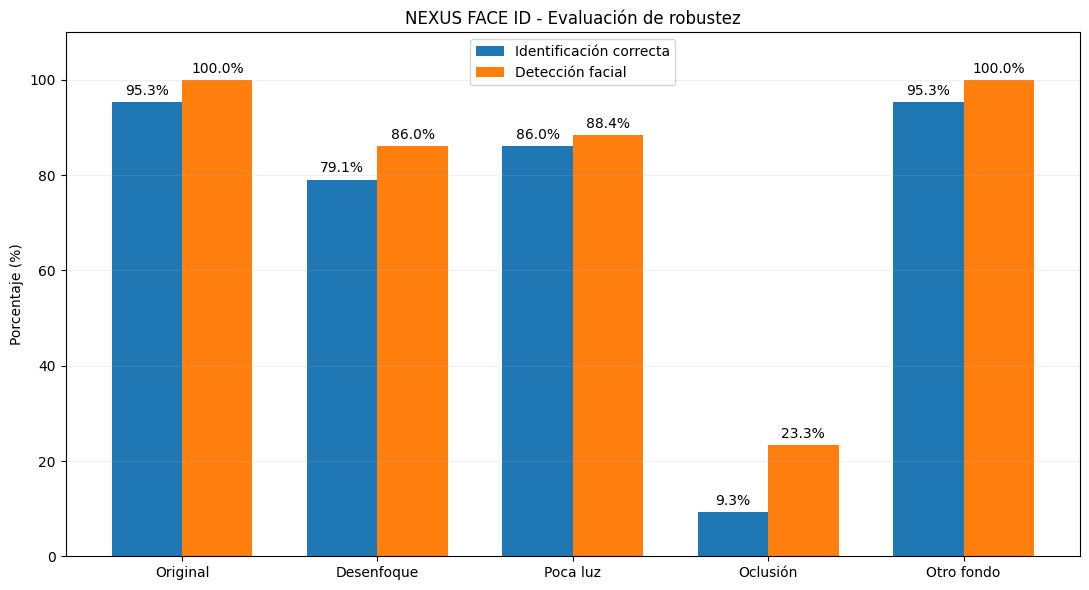

In [43]:
orden = [
    "original",
    "desenfoque",
    "poca_luz",
    "oclusion",
    "otro_fondo"
]

grafica = robust_summary.set_index(
    "condicion"
).reindex(orden)

etiquetas = [
    "Original",
    "Desenfoque",
    "Poca luz",
    "Oclusión",
    "Otro fondo"
]

x = np.arange(len(etiquetas))
ancho = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

barras1 = ax.bar(
    x - ancho / 2,
    grafica["exactitud_pct"],
    ancho,
    label="Identificación correcta"
)

barras2 = ax.bar(
    x + ancho / 2,
    grafica["deteccion_pct"],
    ancho,
    label="Detección facial"
)

ax.set_xticks(x)
ax.set_xticklabels(etiquetas)

ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 110)

ax.set_title(
    "NEXUS FACE ID - Evaluación de robustez"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

ax.bar_label(barras1, fmt="%.1f%%", padding=3)
ax.bar_label(barras2, fmt="%.1f%%", padding=3)

plt.tight_layout()

plt.savefig(
    "/content/S15_grafica_robustez.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [44]:
import zipfile
from pathlib import Path
from google.colab import files

archivos = [
    "S15_robustez_detalle.csv",
    "S15_robustez_resumen.csv",
    "S15_grafica_robustez.png",
    "S15_ejemplo_robustez.png"
]

destino = "/content/NEXUS_S15_ROBUSTEZ.zip"

with zipfile.ZipFile(
    destino, "w",
    zipfile.ZIP_DEFLATED
) as z:

    for nombre in archivos:
        ruta = Path("/content") / nombre

        if ruta.exists():
            z.write(ruta, arcname=nombre)
            print("AGREGADO:", nombre)
        else:
            print("FALTA:", nombre)

files.download(destino)


AGREGADO: S15_robustez_detalle.csv
AGREGADO: S15_robustez_resumen.csv
AGREGADO: S15_grafica_robustez.png
AGREGADO: S15_ejemplo_robustez.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# NEXUS FACE ID - PREPARACIÓN GRAD-CAM

from pathlib import Path
import torch

print("=== MODELO DISPONIBLE ===")

if "student_model_ensemble" in globals():
    print("MobileNetV3-Small: CARGADO")
else:
    print("MobileNetV3-Small: NO CARGADO")

print("\n=== ARCHIVOS DE MODELO ===")

modelos = []

for extension in ("*.pth", "*.pt", "*.onnx"):
    modelos.extend(
        Path("/content").rglob(extension)
    )

for modelo in modelos[:30]:
    print(modelo)

if not modelos:
    print("No se encontraron archivos de pesos.")

print("\n=== GPU ===")
print(
    "CUDA disponible:",
    torch.cuda.is_available()
)


=== MODELO DISPONIBLE ===
MobileNetV3-Small: NO CARGADO

=== ARCHIVOS DE MODELO ===
No se encontraron archivos de pesos.

=== GPU ===
CUDA disponible: False


In [46]:



from google.colab import files
from pathlib import Path

print("Selecciona el archivo .pth de la Semana 14")

uploaded = files.upload()

model_files = [
    Path("/content") / name
    for name in uploaded
    if name.lower().endswith((".pth", ".pt"))
]

if not model_files:
    print("No se subió ningún archivo de modelo.")
else:
    MODEL_PATH = str(model_files[0])
    print("MODELO RECUPERADO:", MODEL_PATH)


Selecciona el archivo .pth de la Semana 14


Saving NEXUS_FACE_ID.ipynb to NEXUS_FACE_ID.ipynb
No se subió ningún archivo de modelo.


In [47]:

# BUSCAR EL ENTRENAMIENTO DE MOBILENET
# DENTRO DEL CUADERNO QUE SUBISTE

import json
from pathlib import Path

ruta = Path("/content/NEXUS_FACE_ID.ipynb")

if not ruta.exists():
    raise FileNotFoundError(
        "No se encuentra NEXUS_FACE_ID.ipynb"
    )

with open(ruta, "r", encoding="utf-8") as f:
    notebook = json.load(f)

palabras = [
    "mobilenet_v3_small",
    "student_model_ensemble",
    "torch.save",
    "distillation",
    "train_loader_student",
    "state_dict"
]

print("=== ANÁLISIS DEL CUADERNO ===")

for i, celda in enumerate(notebook["cells"]):
    codigo = "".join(celda.get("source", []))
    encontrados = [
        palabra
        for palabra in palabras
        if palabra.lower() in codigo.lower()
    ]

    if encontrados:
        print(f"\nCelda {i}")
        print("Coincidencias:", encontrados)
        print("Fragmento:")
        print(codigo[:350])
        print("-" * 45)

print("\nANÁLISIS TERMINADO")


=== ANÁLISIS DEL CUADERNO ===

Celda 45
Coincidencias: ['distillation', 'train_loader_student']
Fragmento:
# Crear puntuaciones docentes leave-one-out para las imágenes de entrenamiento.
# La imagen consultada se excluye del centroide de su propia identidad.
WEIGHT_DLIB = DLIB_WEIGHT
WEIGHT_FACENET = FACENET_WEIGHT
teacher_train_rows = []

for query_index in train_indices_ensemble:
    d_centers, f_centers = [], []

    for class_index in range(len(ense
---------------------------------------------

Celda 46
Coincidencias: ['mobilenet_v3_small', 'student_model_ensemble', 'distillation', 'train_loader_student']
Fragmento:
# Crear y entrenar el estudiante MobileNetV3-Small.
student_model_ensemble = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)
student_model_ensemble.classifier[3] = torch.nn.Linear(
    student_model_ensemble.classifier[3].in_features,
    len(ensemble_classes)
)
student_model_ensemble = student_model_ensemble.to(d
--------------------

In [48]:

from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

print("BUSCANDO MODELOS GUARDADOS...")

encontrados = []

for extension in ["*.pth", "*.pt"]:
    encontrados.extend(
        Path("/content/drive/MyDrive").rglob(extension)
    )

for archivo in encontrados:
    print(archivo)

if not encontrados:
    print("NO SE ENCONTRARON MODELOS GUARDADOS")


Mounted at /content/drive
BUSCANDO MODELOS GUARDADOS...
NO SE ENCONTRARON MODELOS GUARDADOS


In [49]:

from pathlib import Path

print("=== DATOS DISPONIBLES PARA GRAD-CAM ===")

variables = [
    "train_loader_student",
    "test_loader_student",
    "ensemble_classes",
    "soft_targets_ensemble",
    "DISTILLATION_TEMPERATURE",
    "device_ensemble",
    "student_model_ensemble"
]

for nombre in variables:
    print(
        f"{nombre}:",
        "OK" if nombre in globals() else "FALTA"
    )

print("\n=== CARPETAS ===")

rutas = [
    "/content/nexus_s15/personas",
    "/content/nexus_data/personas",
    "/content/nexus_data/desconocidos"
]

for ruta in rutas:
    p = Path(ruta)
    print(ruta, "EXISTE" if p.exists() else "FALTA")

print("\n=== CUADERNO ORIGINAL ===")
print(
    "NEXUS_FACE_ID.ipynb:",
    Path("/content/NEXUS_FACE_ID.ipynb").exists()
)


=== DATOS DISPONIBLES PARA GRAD-CAM ===
train_loader_student: FALTA
test_loader_student: FALTA
ensemble_classes: FALTA
soft_targets_ensemble: FALTA
DISTILLATION_TEMPERATURE: FALTA
device_ensemble: FALTA
student_model_ensemble: FALTA

=== CARPETAS ===
/content/nexus_s15/personas EXISTE
/content/nexus_data/personas FALTA
/content/nexus_data/desconocidos EXISTE

=== CUADERNO ORIGINAL ===
NEXUS_FACE_ID.ipynb: True


In [51]:

# ============================================
# NEXUS FACE ID - GRAD-CAM
# PASO 1: PREPARAR EL ENTRENAMIENTO AUXILIAR
# ============================================

import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image

from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU funciona; GPU es opcional
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATA_DIR = Path("/content/nexus_s15/personas")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "No se encuentra la carpeta personas."
    )

EXTS = {".jpg", ".jpeg", ".png", ".webp"}

# Recoger fotografías e identidades
registros = []

for carpeta in sorted(DATA_DIR.iterdir()):
    if not carpeta.is_dir():
        continue

    fotos = [
        p for p in carpeta.rglob("*")
        if p.suffix.lower() in EXTS
    ]

    for foto in fotos:
        registros.append({
            "archivo": str(foto),
            "identidad": carpeta.name
        })

df_gradcam = pd.DataFrame(registros)

# Solo identidades con al menos 2 fotos
conteos = df_gradcam["identidad"].value_counts()

clases_validas = conteos[
    conteos >= 2
].index.tolist()

df_gradcam = df_gradcam[
    df_gradcam["identidad"].isin(clases_validas)
].copy()

ensemble_classes = sorted(
    df_gradcam["identidad"].unique()
)

class_to_idx = {
    nombre: i
    for i, nombre in enumerate(ensemble_classes)
}

df_gradcam["label"] = df_gradcam[
    "identidad"
].map(class_to_idx)

# Separación por identidad
train_rows = []
test_rows = []

for nombre, grupo in df_gradcam.groupby("identidad"):
    filas = grupo.to_dict("records")
    random.Random(SEED).shuffle(filas)

    n_test = max(1, round(len(filas) * 0.25))

    test_rows.extend(filas[:n_test])
    train_rows.extend(filas[n_test:])

train_df = pd.DataFrame(train_rows)
test_df = pd.DataFrame(test_rows)

# Transformaciones
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fila = self.data.iloc[idx]

        imagen = Image.open(
            fila["archivo"]
        ).convert("RGB")

        return (
            self.transform(imagen),
            int(fila["label"])
        )

train_dataset = FaceDataset(
    train_df, train_transform
)

test_dataset = FaceDataset(
    test_df, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("=== DATOS PREPARADOS ===")
print("Dispositivo:", device)
print("Identidades:", len(ensemble_classes))
print("Entrenamiento:", len(train_df))
print("Prueba:", len(test_df))
print("TOTAL:", len(df_gradcam))


=== DATOS PREPARADOS ===
Dispositivo: cpu
Identidades: 32
Entrenamiento: 193
Prueba: 60
TOTAL: 253


In [52]:

# ============================================
# PASO 2: ENTRENAR MOBILENETV3-SMALL
# ============================================

import copy
import torch.nn.functional as F

# Cargar arquitectura
try:
    model_gradcam = models.mobilenet_v3_small(
        weights=models.MobileNet_V3_Small_Weights.DEFAULT
    )
    print("Pesos preentrenados de ImageNet cargados.")

except Exception as e:
    print("No se pudieron cargar pesos preentrenados.")
    print("Se utilizará inicialización aleatoria.")
    model_gradcam = models.mobilenet_v3_small(
        weights=None
    )

# Adaptar clasificador a nuestras identidades
num_classes = len(ensemble_classes)

model_gradcam.classifier[3] = nn.Linear(
    model_gradcam.classifier[3].in_features,
    num_classes
)

model_gradcam = model_gradcam.to(device)

# Entrenamiento
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_gradcam.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

EPOCHS = 8

historial = []

for epoch in range(EPOCHS):
    model_gradcam.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader:
        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model_gradcam(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += (
            loss.item() * imagenes.size(0)
        )

        pred = salidas.argmax(dim=1)

        correct += (
            pred == etiquetas
        ).sum().item()

        total += etiquetas.size(0)

    train_loss = running_loss / max(total, 1)
    train_acc = correct / max(total, 1)

    # Evaluación
    model_gradcam.eval()

    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for imagenes, etiquetas in test_loader:
            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model_gradcam(imagenes)

            pred = salidas.argmax(dim=1)

            test_correct += (
                pred == etiquetas
            ).sum().item()

            test_total += etiquetas.size(0)

    test_acc = test_correct / max(test_total, 1)

    historial.append({
        "epoch": epoch + 1,
        "loss": train_loss,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

    print(
        f"Época {epoch+1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train: {train_acc*100:.2f}% | "
        f"Test: {test_acc*100:.2f}%"
    )

print("\nENTRENAMIENTO TERMINADO")

historial_df = pd.DataFrame(historial)
display(historial_df)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 54.1MB/s]


Pesos preentrenados de ImageNet cargados.
Época 1/8 | Loss: 3.4627 | Train: 5.18% | Test: 10.00%
Época 2/8 | Loss: 3.1962 | Train: 24.35% | Test: 15.00%
Época 3/8 | Loss: 2.9359 | Train: 40.41% | Test: 21.67%
Época 4/8 | Loss: 2.6566 | Train: 46.63% | Test: 28.33%
Época 5/8 | Loss: 2.3475 | Train: 58.55% | Test: 36.67%
Época 6/8 | Loss: 2.0672 | Train: 63.73% | Test: 50.00%
Época 7/8 | Loss: 1.7701 | Train: 73.06% | Test: 56.67%
Época 8/8 | Loss: 1.4898 | Train: 81.35% | Test: 61.67%

ENTRENAMIENTO TERMINADO


,epoch,loss,train_accuracy,test_accuracy
0,1,3.462689,0.051813,0.100000
1,2,3.196184,0.243523,0.150000
2,3,2.935917,0.404145,0.216667
3,4,2.656585,0.466321,0.283333
4,5,2.347542,0.585492,0.366667
5,6,2.067205,0.637306,0.500000
6,7,1.770095,0.730570,0.566667
7,8,1.489839,0.813472,0.616667


In [53]:

# ============================================
# PASO 3: GUARDAR MODELO EN GOOGLE DRIVE
# ============================================

from pathlib import Path
import torch

CARPETA_MODELOS = Path(
    "/content/drive/MyDrive/NEXUS_FACE_ID/modelos"
)

CARPETA_MODELOS.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = CARPETA_MODELOS / (
    "nexus_mobilenetv3_gradcam_auxiliar.pth"
)

torch.save({
    "state_dict": model_gradcam.state_dict(),
    "classes": ensemble_classes,
    "architecture": "mobilenet_v3_small",
    "training_type": "supervised_auxiliary",
    "seed": SEED
}, MODEL_PATH)

print("MODELO GUARDADO CORRECTAMENTE")
print("Ruta:", MODEL_PATH)

print(
    "Tamaño:",
    round(
        MODEL_PATH.stat().st_size / 1024**2,
        2
    ),
    "MB"
)


MODELO GUARDADO CORRECTAMENTE
Ruta: /content/drive/MyDrive/NEXUS_FACE_ID/modelos/nexus_mobilenetv3_gradcam_auxiliar.pth
Tamaño: 6.05 MB


In [54]:

# ============================================
# PASO 4: EVALUACIÓN PARA GRAD-CAM
# ============================================

model_gradcam.eval()

predicciones_gradcam = []

with torch.no_grad():
    for _, fila in test_df.iterrows():
        imagen = Image.open(
            fila["archivo"]
        ).convert("RGB")

        entrada = test_transform(
            imagen
        ).unsqueeze(0).to(device)

        logits = model_gradcam(entrada)
        probs = torch.softmax(logits, dim=1)

        pred_idx = int(
            probs.argmax(dim=1).item()
        )

        real_idx = int(fila["label"])

        predicciones_gradcam.append({
            "archivo": fila["archivo"],
            "clase_real": fila["identidad"],
            "prediccion": ensemble_classes[pred_idx],
            "confianza": float(
                probs[0, pred_idx].item()
            ),
            "correcto": pred_idx == real_idx
        })

gradcam_df = pd.DataFrame(
    predicciones_gradcam
)

aciertos = gradcam_df[
    gradcam_df["correcto"]
]

errores = gradcam_df[
    ~gradcam_df["correcto"]
]

print("=== RESULTADOS PARA GRAD-CAM ===")
print("Total evaluadas:", len(gradcam_df))
print("Aciertos:", len(aciertos))
print("Errores:", len(errores))

print("\nDisponibles para visualización:")
print("Aciertos:", min(10, len(aciertos)))
print("Errores:", min(10, len(errores)))

gradcam_df.to_csv(
    "/content/S15_gradcam_predicciones.csv",
    index=False,
    encoding="utf-8-sig"
)

display(gradcam_df.head())


=== RESULTADOS PARA GRAD-CAM ===
Total evaluadas: 60
Aciertos: 37
Errores: 23

Disponibles para visualización:
Aciertos: 10
Errores: 10


,archivo,clase_real,prediccion,confianza,correcto
0,"/content/nexus_s15/personas/Beltran Lozano, Yh...","Beltran Lozano, Yhonatan","Blanco Garcia, Daniel",0.139953,False
1,"/content/nexus_s15/personas/Blanco Garcia, Dan...","Blanco Garcia, Daniel",Ingeniero Oscar,0.213597,False
2,"/content/nexus_s15/personas/Blanco Garcia, Dan...","Blanco Garcia, Daniel","Blanco Garcia, Daniel",0.179639,True
3,"/content/nexus_s15/personas/Calderon Mosquera,...","Calderon Mosquera, Juan","Calderon Mosquera, Juan",0.176194,True
4,"/content/nexus_s15/personas/Calderon Mosquera,...","Calderon Mosquera, Juan","Gonzalez Cruz, Juan",0.069619,False


In [55]:

# ============================================
# PASO 5 - CONFIGURAR GRAD-CAM
# NEXUS FACE ID - SEMANA 15
# ============================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from torch.nn import functional as F

model_gradcam.eval()

# Última capa convolucional de características
target_layer = model_gradcam.features[-1]

def calcular_gradcam(ruta_imagen):
    imagen = Image.open(
        ruta_imagen
    ).convert("RGB")

    entrada = test_transform(
        imagen
    ).unsqueeze(0).to(device)

    capturas = {}

    def forward_hook(module, inputs, output):
        capturas["activaciones"] = output.detach()

        def guardar_gradiente(grad):
            capturas["gradientes"] = grad.detach()

        output.register_hook(guardar_gradiente)

    hook = target_layer.register_forward_hook(
        forward_hook
    )

    try:
        model_gradcam.zero_grad(set_to_none=True)

        with torch.enable_grad():
            logits = model_gradcam(entrada)

            clase_predicha = int(
                logits.argmax(dim=1).item()
            )

            confianza = float(
                torch.softmax(logits, dim=1)[
                    0, clase_predicha
                ].item()
            )

            # Explicar la clase que eligió el modelo
            puntuacion = logits[0, clase_predicha]
            puntuacion.backward()

        activaciones = capturas["activaciones"]
        gradientes = capturas["gradientes"]

        pesos = gradientes.mean(
            dim=(2, 3),
            keepdim=True
        )

        mapa = (
            pesos * activaciones
        ).sum(dim=1, keepdim=True)

        mapa = F.relu(mapa)

        mapa = F.interpolate(
            mapa,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        mapa = mapa[0, 0].cpu().numpy()

        mapa_min = float(mapa.min())
        mapa_max = float(mapa.max())

        if mapa_max > mapa_min:
            mapa = (
                (mapa - mapa_min) /
                (mapa_max - mapa_min)
            )
        else:
            mapa = np.zeros_like(mapa)

        imagen_base = imagen.resize((224, 224))

        return {
            "imagen": imagen_base,
            "mapa": mapa,
            "clase_predicha": ensemble_classes[
                clase_predicha
            ],
            "confianza": confianza,
            "mapa_vacio": bool(mapa_max <= mapa_min)
        }

    finally:
        hook.remove()

print("GRAD-CAM CONFIGURADO CORRECTAMENTE")
print("Capa utilizada:", target_layer)


GRAD-CAM CONFIGURADO CORRECTAMENTE
Capa utilizada: Conv2dNormActivation(
  (0): Conv2d(96, 576, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(576, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
  (2): Hardswish()
)


In [56]:


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CARPETA_GRADCAM = Path(
    "/content/S15_GradCAM_NEXUS"
)

CARPETA_GRADCAM.mkdir(
    parents=True,
    exist_ok=True
)

# Seleccionar 10 aciertos y 10 errores
seleccion_aciertos = (
    gradcam_df[gradcam_df["correcto"] == True]
    .sample(n=10, random_state=42)
    .copy()
)

seleccion_errores = (
    gradcam_df[gradcam_df["correcto"] == False]
    .sample(n=10, random_state=42)
    .copy()
)

seleccion_aciertos["grupo"] = "acierto"
seleccion_errores["grupo"] = "error"

seleccion = pd.concat(
    [seleccion_aciertos, seleccion_errores],
    ignore_index=True
)

registros_cam = []

for i, fila in seleccion.iterrows():

    resultado = calcular_gradcam(
        fila["archivo"]
    )

    imagen = np.asarray(
        resultado["imagen"]
    )

    mapa = resultado["mapa"]

    nombre = (
        f"{i+1:02d}_{fila['grupo']}.png"
    )

    salida = CARPETA_GRADCAM / nombre

    # Original, activación y superposición
    fig, axes = plt.subplots(
        1, 3,
        figsize=(12, 4)
    )

    axes[0].imshow(imagen)
    axes[0].set_title("Fotografía original")

    axes[1].imshow(
        mapa,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Mapa Grad-CAM")

    axes[2].imshow(imagen)
    axes[2].imshow(
        mapa,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Superposición")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{fila['grupo'].upper()} | "
        f"Real: {fila['clase_real']} | "
        f"Pred: {resultado['clase_predicha']} | "
        f"Confianza: {resultado['confianza']:.3f}",
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        salida,
        dpi=160,
        bbox_inches="tight"
    )

    plt.close(fig)

    registros_cam.append({
        "archivo_original": fila["archivo"],
        "tipo": fila["grupo"],
        "clase_real": fila["clase_real"],
        "prediccion": resultado["clase_predicha"],
        "confianza": resultado["confianza"],
        "correcto": fila["correcto"],
        "mapa_vacio": resultado["mapa_vacio"],
        "imagen_gradcam": nombre
    })

    print(
        f"Generado {i+1}/20:",
        nombre
    )

gradcam_resultados = pd.DataFrame(
    registros_cam
)

gradcam_resultados.to_csv(
    CARPETA_GRADCAM /
    "S15_gradcam_resultados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n================================")
print("GRAD-CAM FINALIZADO")
print("================================")

print(
    "Aciertos:",
    sum(gradcam_resultados["tipo"] == "acierto")
)

print(
    "Errores:",
    sum(gradcam_resultados["tipo"] == "error")
)

print(
    "Mapas vacíos:",
    gradcam_resultados["mapa_vacio"].sum()
)

display(gradcam_resultados.head())


Generado 1/20: 01_acierto.png
Generado 2/20: 02_acierto.png
Generado 3/20: 03_acierto.png
Generado 4/20: 04_acierto.png
Generado 5/20: 05_acierto.png
Generado 6/20: 06_acierto.png
Generado 7/20: 07_acierto.png
Generado 8/20: 08_acierto.png
Generado 9/20: 09_acierto.png
Generado 10/20: 10_acierto.png
Generado 11/20: 11_error.png
Generado 12/20: 12_error.png
Generado 13/20: 13_error.png
Generado 14/20: 14_error.png
Generado 15/20: 15_error.png
Generado 16/20: 16_error.png
Generado 17/20: 17_error.png
Generado 18/20: 18_error.png
Generado 19/20: 19_error.png
Generado 20/20: 20_error.png

GRAD-CAM FINALIZADO
Aciertos: 10
Errores: 10
Mapas vacíos: 0


,archivo_original,tipo,clase_real,prediccion,confianza,correcto,mapa_vacio,imagen_gradcam
0,/content/nexus_s15/personas/Ingeniero Oscar/8 ...,acierto,Ingeniero Oscar,Ingeniero Oscar,0.688447,True,False,01_acierto.png
1,/content/nexus_s15/personas/Ingeniero Dennis/D...,acierto,Ingeniero Dennis,Ingeniero Dennis,0.325101,True,False,02_acierto.png
2,/content/nexus_s15/personas/David Vargas/David...,acierto,David Vargas,David Vargas,0.522879,True,False,03_acierto.png
3,/content/nexus_s15/personas/Miguel Melo/Miguel...,acierto,Miguel Melo,Miguel Melo,0.320813,True,False,04_acierto.png
4,/content/nexus_s15/personas/pp/WhatsApp Image ...,acierto,pp,pp,0.079248,True,False,05_acierto.png


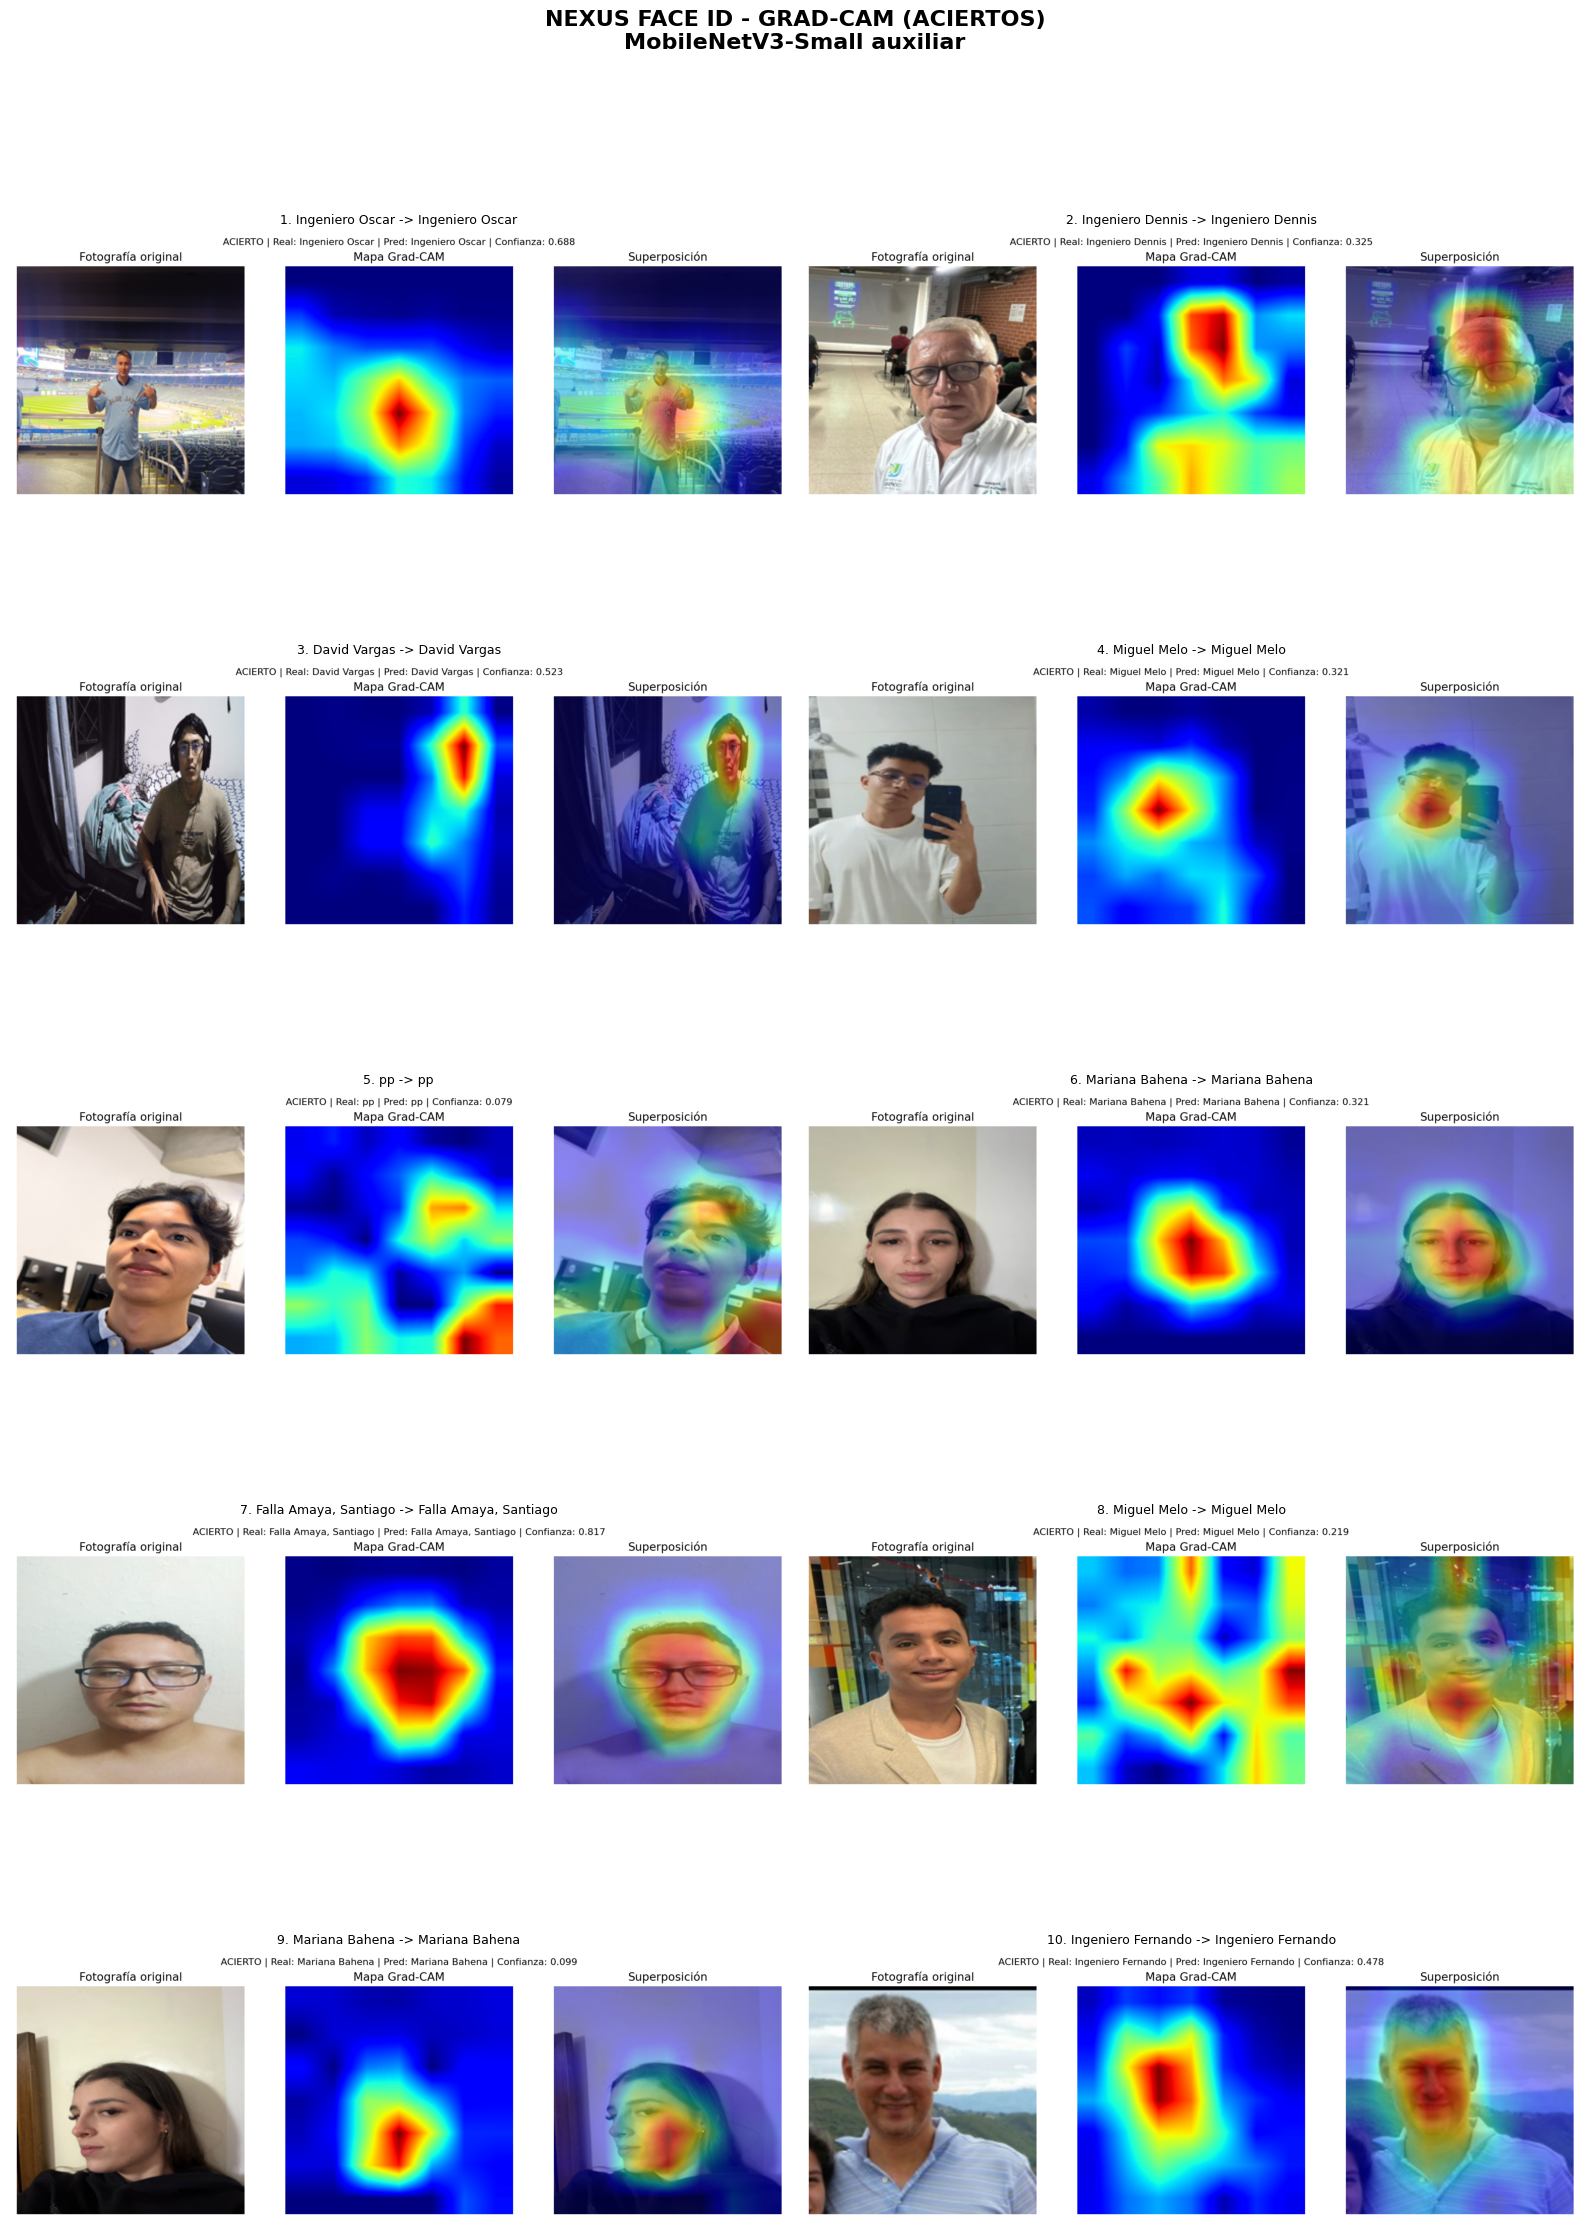

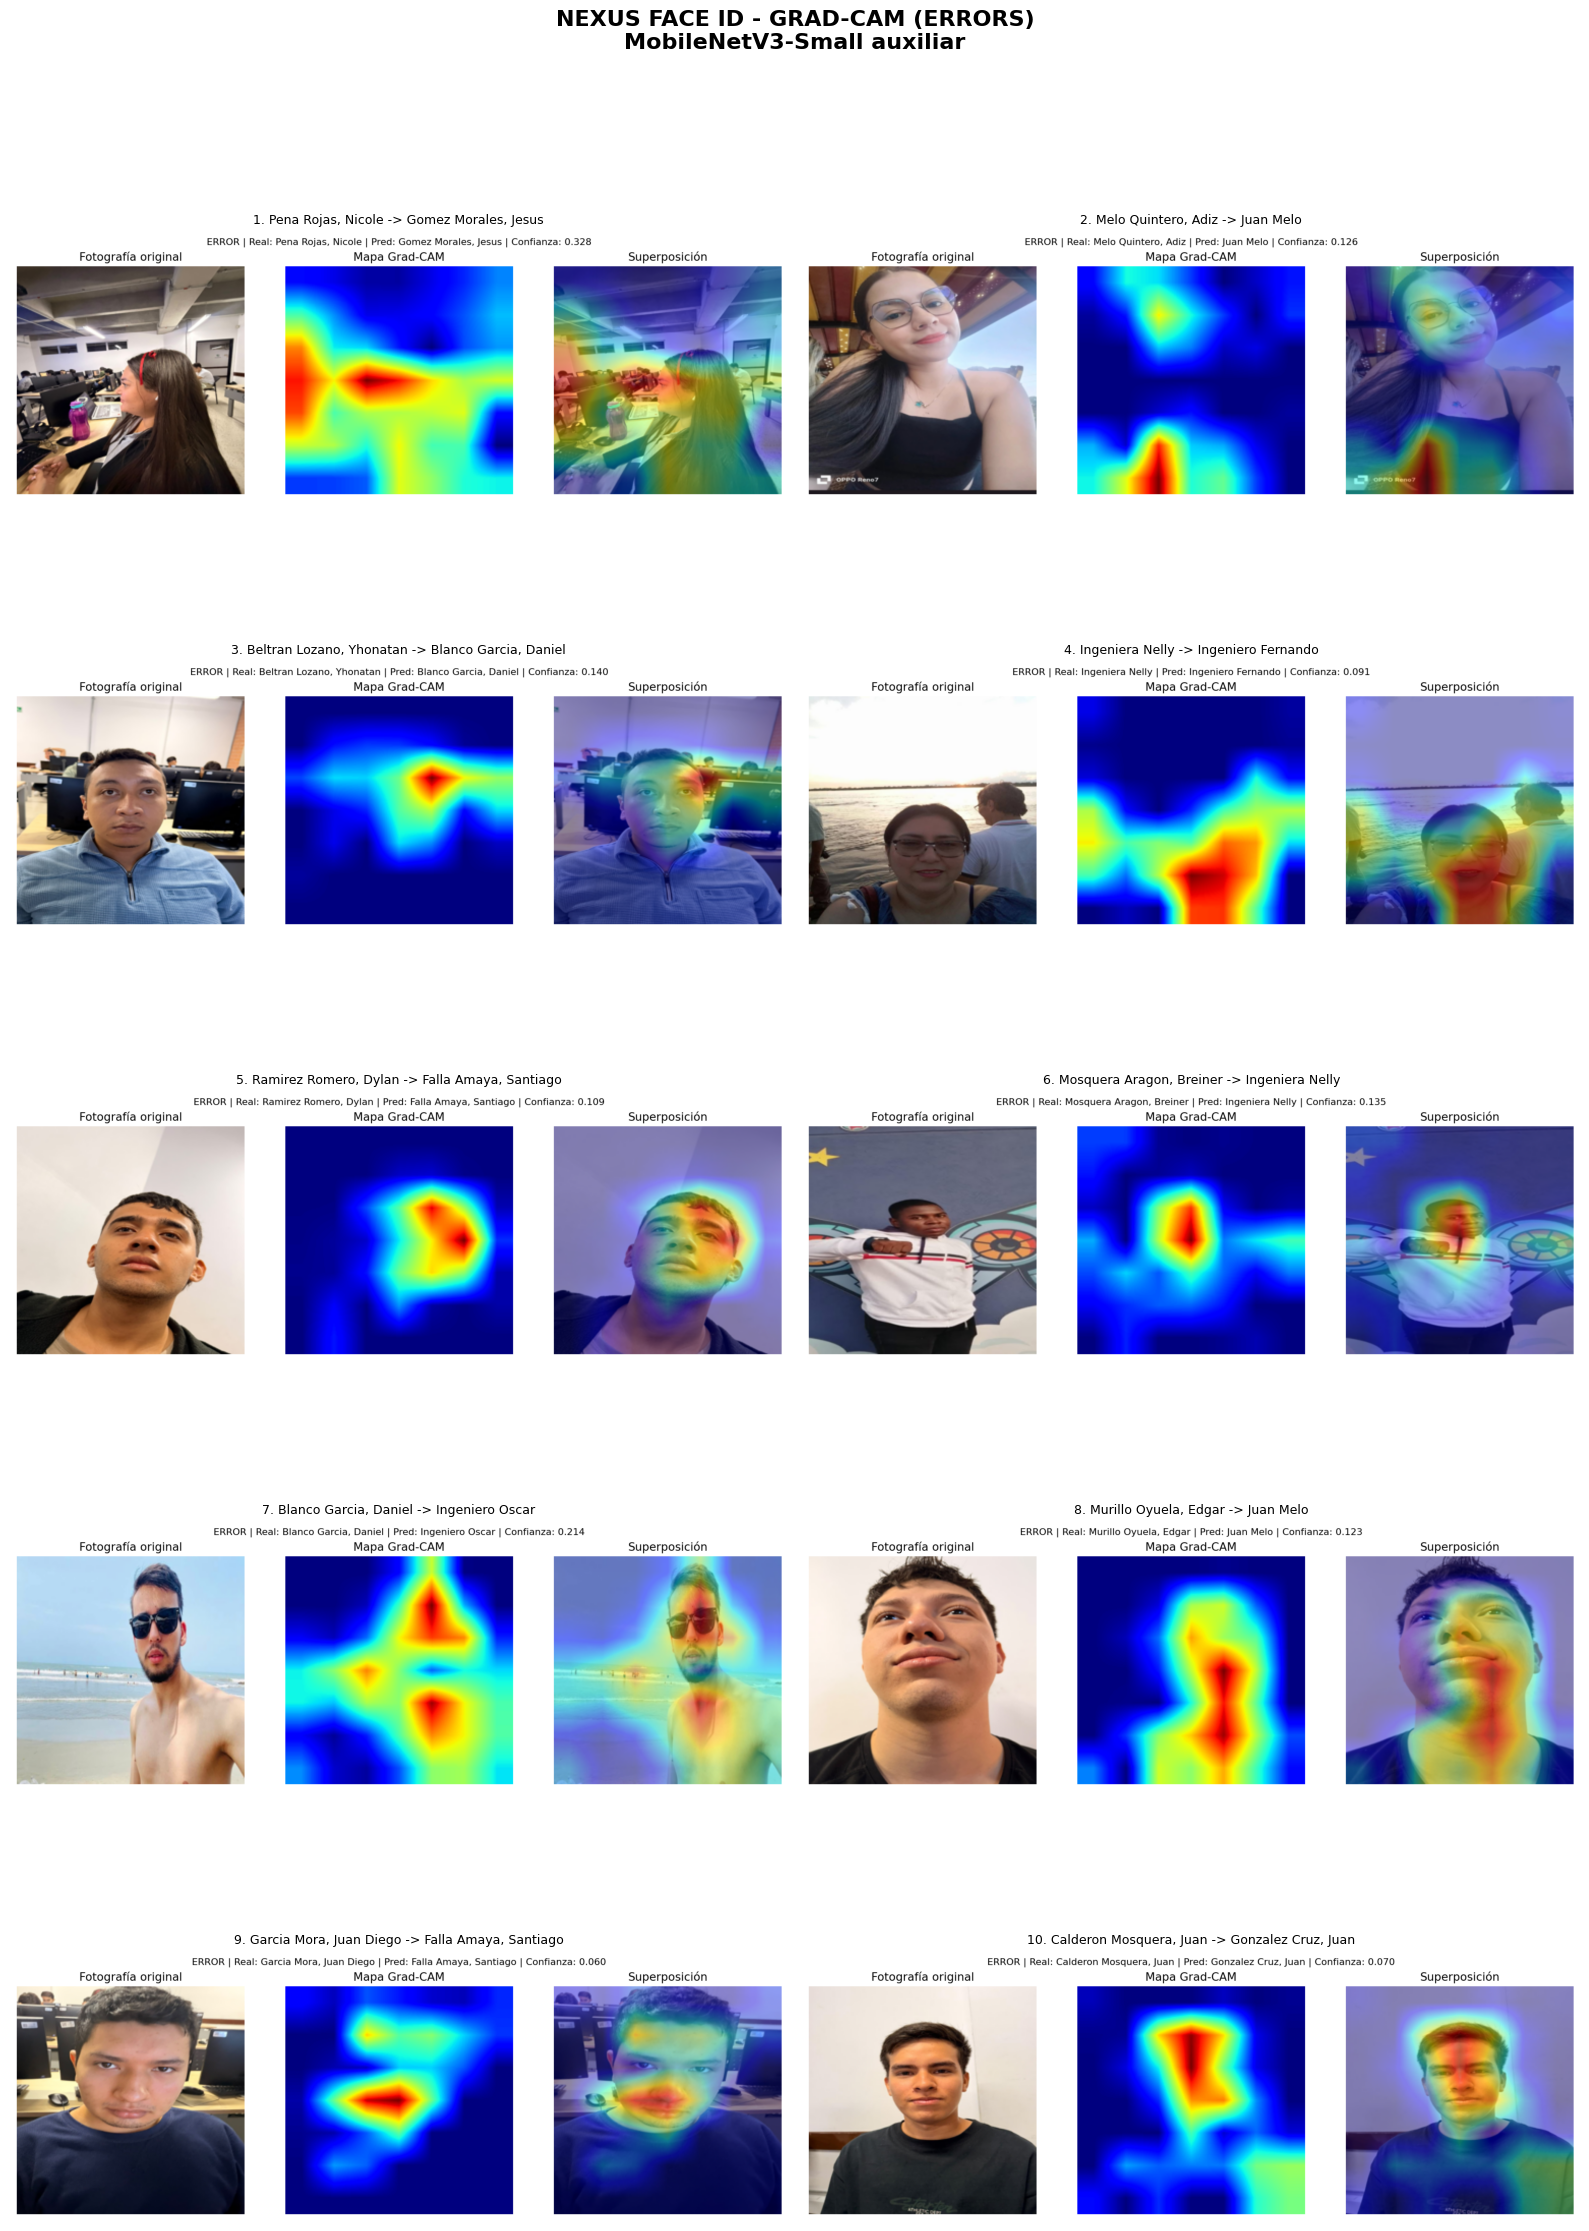

LÁMINAS COMPARATIVAS GENERADAS


In [57]:

# ============================================
# PASO 7 - LÁMINAS DE GRAD-CAM
# ============================================

from PIL import Image
import matplotlib.pyplot as plt

for grupo in ["acierto", "error"]:

    subset = gradcam_resultados[
        gradcam_resultados["tipo"] == grupo
    ].reset_index(drop=True)

    fig, axes = plt.subplots(
        5, 2,
        figsize=(16, 24)
    )

    for i, ax in enumerate(axes.flat):
        if i < len(subset):
            fila = subset.iloc[i]

            imagen = Image.open(
                CARPETA_GRADCAM /
                fila["imagen_gradcam"]
            )

            ax.imshow(imagen)

            ax.set_title(
                f"{i+1}. {fila['clase_real']} "
                f"-> {fila['prediccion']}",
                fontsize=9
            )

        ax.axis("off")

    fig.suptitle(
        f"NEXUS FACE ID - GRAD-CAM "
        f"({grupo.upper()}S)\n"
        "MobileNetV3-Small auxiliar",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    salida = (
        CARPETA_GRADCAM /
        f"S15_GradCAM_{grupo}s_resumen.png"
    )

    plt.savefig(
        salida,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("LÁMINAS COMPARATIVAS GENERADAS")


In [58]:

# ============================================
# PASO 8 - DESCARGAR GRAD-CAM
# ============================================

import zipfile
from google.colab import files

ZIP_GRADCAM = (
    "/content/NEXUS_S15_GRADCAM.zip"
)

with zipfile.ZipFile(
    ZIP_GRADCAM,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for archivo in CARPETA_GRADCAM.rglob("*"):
        if archivo.is_file():
            zipf.write(
                archivo,
                arcname=archivo.relative_to(
                    CARPETA_GRADCAM
                )
            )

print("ZIP GENERADO CORRECTAMENTE")

files.download(ZIP_GRADCAM)


ZIP GENERADO CORRECTAMENTE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>